In [ ]:
import os, json, warnings, calendar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import KNNImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor, VotingRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

DATA_CANDIDATES = [
    "dataset/Sensor Data Jan - July 2026.csv",
    "/mnt/user-data/uploads/Sensor_Data_Jan_-_July_2026.csv",
]
DATA_PATH = next((p for p in DATA_CANDIDATES if os.path.exists(p)), None)
assert DATA_PATH is not None, "Put the csv inside a data/ folder next to this file"

OUT_DIR, FIG_DIR, MODEL_DIR = "outputs", "outputs/figures", "models"
for folder in [OUT_DIR, FIG_DIR, MODEL_DIR]:
    os.makedirs(folder, exist_ok=True)

# AQI bands
AQI_EDGES   = [-np.inf, 9.1, 35.49, 55.49, 125.49, 225.49, np.inf]
AQI_NAMES   = ["Good", "Moderate", "Unhealthy for Sensitive Groups", "Unhealthy", "Very Unhealthy", "Hazardous"]
AQI_COLOURS = ["#00e400", "#ffff00", "#ff7e00", "#ff0000", "#8f3f97", "#7e0023"]

def aqi_category(values):
    """turn PM2.5 numbers into the AQI band names (values between 9 and 9.101 are put in Good)"""
    return pd.cut(np.asarray(values, dtype=float), bins=AQI_EDGES, labels=AQI_NAMES)   # always a Categorical (has .codes)

def add_aqi_bands(ax, ymax):
    """paint the six AQI bands as coloured stripes behind a time series"""
    lows  = [0, 9.1, 35.49, 55.49, 125.49, 225.49]
    highs = [9.1, 35.49, 55.49, 125.49, 225.49, max(ymax, 300)]
    for lo, hi, colour in zip(lows, highs, AQI_COLOURS):
        ax.axhspan(lo, hi, color=colour, alpha=0.18, lw=0)
    ax.set_ylim(0, ymax)

def aqi_legend_handles():
    return [mpatches.Patch(color=c, alpha=0.6, label=n) for c, n in zip(AQI_COLOURS, AQI_NAMES)]

def save_fig(name):
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

print("data file:", DATA_PATH)

raw = pd.read_csv(DATA_PATH)
print("rows, columns:", raw.shape)
print(raw.dtypes)
raw.head(3)

data file: dataset/Sensor Data Jan - July 2026.csv
rows, columns: (14600, 12)
site_name                     str
datetime                      str
frequency                     str
network                       str
latitude                  float64
longitude                 float64
temperature               float64
humidity                  float64
pm2_5_calibrated_value    float64
pm10_calibrated_value     float64
site_id                       str
device_name                   str
dtype: object


,site_name,datetime,frequency,network,latitude,longitude,temperature,humidity,pm2_5_calibrated_value,pm10_calibrated_value,site_id,device_name
0,Salama Road,2026-01-01 00:00:00Z,hourly,airgradient,0.33354,32.56861,20.535000,88.405000,181.16,197.89,694140834973ef0013d1a9b0,ag_588c81267534
1,Salama Road,2026-01-01 01:00:00Z,hourly,airgradient,0.33354,32.56861,20.640000,89.610000,290.98,318.91,694140834973ef0013d1a9b0,ag_588c81267534
2,Salama Road,2026-01-01 02:00:00Z,hourly,airgradient,0.33354,32.56861,20.821053,89.610526,274.59,301.09,694140834973ef0013d1a9b0,ag_588c81267534


###1 Data preparation
a_Data types and the time zone

In [2]:
df = raw.copy()
df = df.rename(columns={"temperature": "temp", "pm2_5_calibrated_value": "pm2_5", "pm10_calibrated_value": "pm10"})

df["datetime"] = pd.to_datetime(df["datetime"], utc=True).dt.tz_convert("Africa/Kampala")

number_cols = ["latitude", "longitude", "temp", "humidity", "pm2_5", "pm10"]
text_cols   = ["site_name", "device_name", "site_id", "network", "frequency"]
for c in number_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
for c in text_cols:
    df[c] = df[c].astype("string")

print(df.dtypes)
month_summary = df.groupby(df['datetime'].dt.to_period('M'))['datetime'].agg(['min', 'max'])
month_summary

site_name                              string
datetime       datetime64[us, Africa/Kampala]
frequency                              string
network                                string
latitude                              float64
longitude                             float64
temp                                  float64
humidity                              float64
pm2_5                                 float64
pm10                                  float64
site_id                                string
device_name                            string
dtype: object


,min,max
datetime,,
2026-01,2026-01-01 03:00:00+03:00,2026-01-03 03:00:00+03:00
2026-04,2026-04-01 03:00:00+03:00,2026-04-03 00:00:00+03:00
2026-06,2026-06-01 03:00:00+03:00,2026-06-03 06:00:00+03:00


b_Zeros are nulls

In [3]:
zero_cols = ["temp", "humidity", "pm2_5", "pm10", "latitude", "longitude"]
empty_before = df[zero_cols].isna().sum()
zeros_found  = (df[zero_cols] == 0).sum()

df[zero_cols] = df[zero_cols].mask(df[zero_cols] == 0)

null_table = pd.DataFrame({
    "empty_in_file": empty_before,
    "zeros_found": zeros_found,
    "null_after": df[zero_cols].isna().sum(),
})
null_table["percent_null_after"] = (100 * null_table["null_after"] / len(df)).round(1)
null_table

,empty_in_file,zeros_found,null_after,percent_null_after
temp,54,4066,4120,28.2
humidity,206,4159,4365,29.9
pm2_5,325,0,325,2.2
pm10,427,3,430,2.9
latitude,1,3085,3086,21.1
longitude,0,3067,3067,21.0


c_Which column identifies a sensor?

In [4]:
print("duplicate rows for (device, hour):", df.duplicated(["device_name", "datetime"]).sum())
print("duplicate rows for (site,   hour):", df.duplicated(["site_name", "datetime"]).sum())
print("number of devices:", df["device_name"].nunique(), "| number of site names:", df["site_name"].nunique())
print("\ndevices per site name:")
print(df.groupby("site_name")["device_name"].nunique().value_counts())

duplicate rows for (device, hour): 0
duplicate rows for (site,   hour): 231
number of devices: 149 | number of site names: 145

devices per site name:
device_name
1    142
2      2
3      1
Name: count, dtype: int64


We decided to use device_name, not site_name. Some sites have 2-3 devices, which is why site_name repeats the
same hour.

d_Sensor location

In [5]:
gps_range_km = df.groupby("device_name")["latitude"].agg(lambda s: s.max() - s.min()) * 111   # 1 degree is about 111 km
print("devices whose reported position moves by more than 1 km:", int((gps_range_km > 1).sum()), "out of", len(gps_range_km))
print("\nbiggest movements (km):")
print(gps_range_km.sort_values(ascending=False).head(5).round(1))

devices whose reported position moves by more than 1 km: 49 out of 149

biggest movements (km):
device_name
aq_g5_79       157.0
airqo_g5437     61.8
airqo_g5544     61.6
airqo_g5481     61.6
airqo_g5545     57.6
Name: latitude, dtype: float64


A fixed monitor cannot move 30 km so we treat these as GPS errors and give each device one location = the median of its
readings. If a device has no valid GPS at all, we try another device with the same site name. (6 devices failed)

In [6]:
device_info = df.groupby("device_name").agg(
    site_name=("site_name", "first"),
    network=("network", "first"),
    latitude=("latitude", "median"),
    longitude=("longitude", "median"),
).reset_index()

site_location = df.groupby("site_name")[["latitude", "longitude"]].median()
no_gps = device_info["latitude"].isna()
device_info.loc[no_gps, "latitude"]  = device_info.loc[no_gps, "site_name"].map(site_location["latitude"])
device_info.loc[no_gps, "longitude"] = device_info.loc[no_gps, "site_name"].map(site_location["longitude"])

device_info["coords_guessed"] = device_info["latitude"].isna()
print("devices with no usable GPS:", int(device_info["coords_guessed"].sum()))
print(device_info.loc[device_info["coords_guessed"], ["device_name", "site_name"]].to_string(index=False))

device_info["latitude"]  = device_info["latitude"].fillna(device_info["latitude"].median())
device_info["longitude"] = device_info["longitude"].fillna(device_info["longitude"].median())

devices with no usable GPS: 6
device_name                 site_name
airqo_g5367   Bakuli, Kampala, Uganda
      aq_43 Makindye, Lukuli Makindye
      aq_54          Kalerwe, Kawempe
      aq_79            Ntinda, Nakawa
    aq_g518   Kivubuka Budondo, Jinja
   aq_g5_50    Rushoroza Hill, Kabale


e_Outliers
Two checks

1. **Physical range.** AirQo monitors measure PM2.5 and PM10 in the range 0-500 ug/m3 [2]. A value above 500 is outside
   what the instrument can measure. In this file the only such values are isolated spikes on one device
   (for example 793 ug/m3 followed by 21.8 an hour later), which is a sensor fault, not air. These become null.
2. **IQR rule, as in Lee et al. [1].** A value above Q3 + 1.5*IQR is *flagged* (I use each sensor's own Q1/Q3). Lee et al. then
   check whether the flagged PM2.5 values move together with PM10; if they do, the high values are real pollution episodes and
   should **not** be deleted. I do the same check.

In [7]:
outlier_log = []

for c in ["pm2_5", "pm10"]:
    too_high = df[c] > 500
    outlier_log.append({"check": f"{c} above 500 ug/m3 (outside sensor range)", "rows": int(too_high.sum()), "action": "set to null"})
    df.loc[too_high, c] = np.nan

def iqr_upper_bound(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    return q3 + 1.5 * (q3 - q1)

df["pm2_5_upper"]    = df.groupby("device_name")["pm2_5"].transform(iqr_upper_bound)
df["pm2_5_iqr_flag"] = df["pm2_5"] > df["pm2_5_upper"]

flagged = df[df["pm2_5_iqr_flag"] & df["pm10"].notna()]
r_flagged = flagged["pm2_5"].corr(flagged["pm10"])
outlier_log.append({"check": "pm2_5 above its sensor's Q3 + 1.5*IQR", "rows": int(df["pm2_5_iqr_flag"].sum()),
                    "action": f"kept (corr with PM10 among flagged rows = {r_flagged:.2f})"})

print(pd.DataFrame(outlier_log).to_string(index=False))
print(f"\nflagged rows are {100*df['pm2_5_iqr_flag'].sum()/df['pm2_5'].notna().sum():.1f}% of all PM2.5 readings")

                                       check  rows                                          action
pm2_5 above 500 ug/m3 (outside sensor range)     3                                     set to null
 pm10 above 500 ug/m3 (outside sensor range)     4                                     set to null
       pm2_5 above its sensor's Q3 + 1.5*IQR   639 kept (corr with PM10 among flagged rows = 0.84)

flagged rows are 4.5% of all PM2.5 readings


Decision: The flagged high values are strongly correlated with PM10 so following [1] we keep them: they are real episodes (dry season, rush hour), and deleting them would teach the model that Kampala is cleaner than it is
[2]. Only the three impossible values above 500 are removed. Tree models are not sensitive to a few extreme values anyway.

f_Complete hourly index per sensor (1 Jan - 31 Jul 2026)

In [8]:
all_hours = pd.date_range("2026-01-01 00:00", "2026-07-31 23:00", freq="h", tz="Africa/Kampala")
devices = sorted(df["device_name"].unique())

grid = pd.MultiIndex.from_product([devices, all_hours], names=["device_name", "datetime"]).to_frame(index=False)
value_cols = ["temp", "humidity", "pm2_5", "pm10"]
data = grid.merge(df[["device_name", "datetime"] + value_cols], on=["device_name", "datetime"], how="left")
data = data.merge(device_info[["device_name", "site_name", "network", "latitude", "longitude", "coords_guessed"]],
                  on="device_name", how="left")

print("grid shape:", data.shape, "=", len(devices), "sensors x", len(all_hours), "hours")
print("every sensor has the same number of rows:", data.groupby("device_name").size().nunique() == 1)

grid shape: (758112, 11) = 149 sensors x 5088 hours
every sensor has the same number of rows: True


g_Look at *when* the data actually exists

Before imputing anything we want to know what kind of missing data we have.

In [9]:
per_day = df.groupby(df["datetime"].dt.date).size()
print(per_day)
print("\ndays with any data:", len(per_day), "out of", len(all_hours) // 24, "days in the grid")

datetime
2026-01-01    2091
2026-01-02    2566
2026-01-03     343
2026-04-01    2091
2026-04-02    2446
2026-04-03      63
2026-06-01    2067
2026-06-02    2374
2026-06-03     559
dtype: int64

days with any data: 9 out of 212 days in the grid


| Kind | Meaning | What I do |
|---|---|---|
| `not_sampled` | the hour is outside the three windows, nobody measured it | stays missing, never imputed (inventing 97% of the data would be fiction) |
| `gap` | the hour is *inside* a window but the sensor sent nothing (device offline / network down) | candidate for imputation |


In [10]:
df["month"] = df["datetime"].dt.month
windows = df.groupby("month")["datetime"].agg(["min", "max"])
print(windows)

data["burst"] = 0                      # 0 = outside the sampled windows
for month, row in windows.iterrows():
    inside = (data["datetime"] >= row["min"]) & (data["datetime"] <= row["max"])
    data.loc[inside, "burst"] = month
data["in_burst"] = data["burst"] > 0

data["status"] = np.where(~data["in_burst"], "not_sampled", np.where(data["pm2_5"].isna(), "gap", "observed"))
print()
print(data["status"].value_counts())
print((100 * data["status"].value_counts(normalize=True)).round(1).astype(str) + " %")

                            min                       max
month                                                    
1     2026-01-01 03:00:00+03:00 2026-01-03 03:00:00+03:00
4     2026-04-01 03:00:00+03:00 2026-04-03 00:00:00+03:00
6     2026-06-01 03:00:00+03:00 2026-06-03 06:00:00+03:00

status
not_sampled    736209
observed        14272
gap              7631
Name: count, dtype: int64
status
not_sampled    97.1 %
observed        1.9 %
gap             1.0 %
Name: proportion, dtype: str


Only the hours inside the three windows are used (the rest of the grid is kept as missing). We also add the hour of the day as a sine/cosine pair so that 23:00 and 00:00 are neighbours for the models.

In [11]:
burst_data = data[data["in_burst"]].copy().reset_index(drop=True)
burst_data["hour"] = burst_data["datetime"].dt.hour
burst_data["hour_sin"] = np.sin(2 * np.pi * burst_data["hour"] / 24)
burst_data["hour_cos"] = np.cos(2 * np.pi * burst_data["hour"] / 24)
print("rows inside the windows:", burst_data.shape)

miss_in_windows = (100 * burst_data[["pm2_5", "pm10", "temp", "humidity"]].isna().mean()).round(1)
print("\n% missing inside the windows:")
print(miss_in_windows)

rows inside the windows: (21903, 17)

% missing inside the windows:
pm2_5       34.8
pm10        35.3
temp        52.2
humidity    53.3
dtype: float64


h_What kinds of gaps do I have inside the windows?
Whether to impute depends on the length and position of the gap, so I list them first

In [12]:
def list_gaps(frame, col):
    """go through every (sensor, window) series and record each run of missing hours"""
    rows = []
    for (dev, win), g in frame.groupby(["device_name", "burst"]):
        missing = g[col].isna().to_numpy()
        n = len(missing)
        if missing.all():
            rows.append(("sensor sent nothing in this window", n))
            continue
        first = int(np.argmax(~missing))                 # first hour with a reading
        last = n - 1 - int(np.argmax(~missing[::-1]))    # last hour with a reading
        if first > 0:
            rows.append(("start of window (no reading before)", first))
        if last < n - 1:
            rows.append(("end of window (no reading after)", n - 1 - last))
        i = first
        while i <= last:
            if missing[i]:
                j = i
                while j <= last and missing[j]:
                    j += 1
                rows.append(("inside (readings on both sides)", j - i))
                i = j
            else:
                i += 1
    return pd.DataFrame(rows, columns=["kind", "hours"])

gaps = list_gaps(burst_data, "pm2_5")
inside = gaps[gaps["kind"].str.startswith("inside")]

print("PM2.5 gaps inside windows, by length:")
length_bucket = pd.cut(inside["hours"], [0, 3, 6, 9, 12, 15, 18, 21, 24, 500], labels=["1-3 h", "4-6 h", "7-9 h","10-12 h","13-15 h","16-18 h","19-21 h","22-24 h", "over 24 h"])
print(pd.DataFrame({"gaps": inside.groupby(length_bucket).size(),
                    "missing hours": inside.groupby(length_bucket)["hours"].sum()}))

print("\nall missing PM2.5 hours inside the windows, by kind:")
print(gaps.groupby("kind")["hours"].agg(["count", "sum"]).rename(columns={"count": "gaps", "sum": "missing hours"}))

PM2.5 gaps inside windows, by length:
           gaps  missing hours
hours                         
1-3 h       542            806
4-6 h        95            447
7-9 h        28            213
10-12 h      14            161
13-15 h       9            126
16-18 h      13            217
19-21 h       5             97
22-24 h       1             23
over 24 h     2             73

all missing PM2.5 hours inside the windows, by kind:
                                     gaps  missing hours
kind                                                    
end of window (no reading after)      230           1042
inside (readings on both sides)       709           2163
sensor sent nothing in this window     75           3687
start of window (no reading before)   110            739


Most gaps inside a window are short (a few hours), which is typical for 2G / solar sensors dropping a few transmissions.
The big blocks of missing hours are at the edges or whole windows where a sensor was offline. There is nothing
before/after them to interpolate from, so we do not invent values there.

i_Which imputation method?

Methods: forward fill, linear interpolation, KNN (k = 11 as in [1]), MICE (`IterativeImputer`). For temp and humidity we add two
"look at the other sensors" methods, because weather is similar across a city: the **nearest sensor** at the same hour, and the
**median of all sensors** at that hour. (AirQo's own calibration challenge notes that temperature and humidity are almost
the same across Kampala weather stations at the same time [4].)

In [13]:
IMPUTE_FEATURES = ["pm2_5", "pm10", "temp", "humidity", "hour_sin", "hour_cos", "latitude", "longitude"]

# nearest-sensor lookup: for every sensor a list of the other sensors sorted by distance.
# (distance in degrees is fine here, Uganda is on the equator so 1 degree is about 111 km both ways)
located = device_info[~device_info["coords_guessed"]].reset_index(drop=True)
lat, lon = located["latitude"].to_numpy(), located["longitude"].to_numpy()
distance = np.sqrt((lat[:, None] - lat[None, :]) ** 2 + (lon[:, None] - lon[None, :]) ** 2)
nearest_order = {}
for i, name in enumerate(located["device_name"]):
    nearest_order[name] = [located["device_name"][k] for k in np.argsort(distance[i]) if k != i]


def fill_from_other_sensors(frame, col, use_nearest=True):
    """fill every missing value of `col` using the other sensors at the SAME hour.
    use_nearest=True : value of the nearest sensor that has a reading (else the median of all sensors)
    use_nearest=False: median of all sensors at that hour
    returns an array in the same row order as `frame`."""
    wide = frame.pivot(index="datetime", columns="device_name", values=col)     # rows = hours, columns = sensors
    original = wide.to_numpy()
    filled = original.copy()
    sensors = list(wide.columns)
    position = {s: i for i, s in enumerate(sensors)}
    hour_median = np.nanmedian(original, axis=1)
    for t in range(original.shape[0]):
        for j in np.where(np.isnan(original[t]))[0]:
            value = np.nan
            if use_nearest:
                for other in nearest_order.get(sensors[j], []):
                    if not np.isnan(original[t, position[other]]):
                        value = original[t, position[other]]
                        break
            if np.isnan(value):
                value = hour_median[t]
            filled[t, j] = value
    time_pos = {t: i for i, t in enumerate(wide.index)}
    rows = frame["datetime"].map(time_pos).to_numpy()
    cols = frame["device_name"].map(position).to_numpy()
    return filled[rows, cols]


def find_blocks(frame, col, length, n_blocks, seed):
    """start positions of `n_blocks` places where `col` is observed for `length` hours in a row,
    with 3 observed hours before and after (so forward fill / interpolation have something to start from)"""
    rng = np.random.default_rng(seed)
    starts = []
    for (dev, win), g in frame.groupby(["device_name", "burst"]):
        ok = g[col].notna().to_numpy()
        positions = g.index.to_numpy()
        good = [i for i in range(3, len(g) - length - 3) if ok[i - 3: i + length + 3].all()]
        if good:
            starts.append(positions[rng.choice(good)])
    rng.shuffle(starts)
    return starts[:n_blocks]


def run_block_test(frame, col, length, n_blocks=100, seed=1, spatial=False):
    starts = find_blocks(frame, col, length, n_blocks, seed)
    hidden = np.concatenate([np.arange(s, s + length) for s in starts])
    truth = frame.loc[hidden, col].to_numpy()
    guesses = {}

    # forward fill and linear interpolation
    ffill_guess, linear_guess = [], []
    for s in starts:
        before, after = frame.at[s - 1, col], frame.at[s + length, col]
        for k in range(length):
            ffill_guess.append(before)
            linear_guess.append(before + (after - before) * (k + 1) / (length + 1))
    guesses["forward fill"] = np.array(ffill_guess)
    guesses["linear interpolation"] = np.array(linear_guess)

    # KNN and MICE use all the other columns (scaled first so no column dominates the distance)
    X = frame[IMPUTE_FEATURES].copy()
    X.loc[hidden, col] = np.nan
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    j = IMPUTE_FEATURES.index(col)
    knn_out = KNNImputer(n_neighbors=11).fit_transform(X_scaled)
    mice_out = IterativeImputer(max_iter=10, random_state=SEED).fit_transform(X_scaled)
    guesses["KNN (k=11)"] = knn_out[hidden, j] * scaler.scale_[j] + scaler.mean_[j]
    guesses["MICE"] = mice_out[hidden, j] * scaler.scale_[j] + scaler.mean_[j]

    if spatial:
        hidden_frame = frame.copy()
        hidden_frame.loc[hidden, col] = np.nan
        guesses["nearest sensor, same hour"] = fill_from_other_sensors(hidden_frame, col, use_nearest=True)[hidden]
        guesses["median of all sensors, same hour"] = fill_from_other_sensors(hidden_frame, col, use_nearest=False)[hidden]

    results = []
    for method, guess in guesses.items():
        results.append({
            "variable": col, "gap_hours": length, "method": method, "blocks": len(starts),
            "RMSE": np.sqrt(np.mean((guess - truth) ** 2)),
            "MAE": np.mean(np.abs(guess - truth)),
        })
    return results

In [14]:
benchmark = []
# Run block tests with our new short-gap candidates (2, 3) as well as the original ones (6, 12, 24)
for col in ["pm2_5", "temp", "humidity"]:
    for length in [3, 6, 9, 12, 15, 18, 21, 24]:
        benchmark += run_block_test(burst_data, col, length, spatial=(col != "pm2_5"))
        print("done:", col, length, "h")

benchmark = pd.DataFrame(benchmark)
benchmark.to_csv(f"{OUT_DIR}/imputation_benchmark.csv", index=False)

for col in ["pm2_5", "temp", "humidity"]:
    print(f"\n=== {col}: RMSE by method and gap length (lower is better) ===")
    print(benchmark[benchmark["variable"] == col].pivot(index="method", columns="gap_hours", values="RMSE").round(2))

done: pm2_5 3 h
done: pm2_5 6 h
done: pm2_5 9 h
done: pm2_5 12 h
done: pm2_5 15 h
done: pm2_5 18 h
done: pm2_5 21 h
done: pm2_5 24 h
done: temp 3 h
done: temp 6 h
done: temp 9 h
done: temp 12 h
done: temp 15 h
done: temp 18 h
done: temp 21 h
done: temp 24 h
done: humidity 3 h
done: humidity 6 h
done: humidity 9 h
done: humidity 12 h
done: humidity 15 h
done: humidity 18 h
done: humidity 21 h
done: humidity 24 h

=== pm2_5: RMSE by method and gap length (lower is better) ===
gap_hours                3      6      9      12     15     18     21     24
method                                                                      
KNN (k=11)             8.13  12.52  10.77   9.32  11.55  11.72  11.00  11.89
MICE                   6.90  10.64   9.98   7.34   8.82   9.04   9.15   9.92
forward fill          28.03  24.93  23.87  23.36  26.79  27.44  31.58  26.53
linear interpolation  17.28  17.97  19.73  21.58  26.09  26.11  26.55  26.48

=== temp: RMSE by method and gap length (lower is better) 

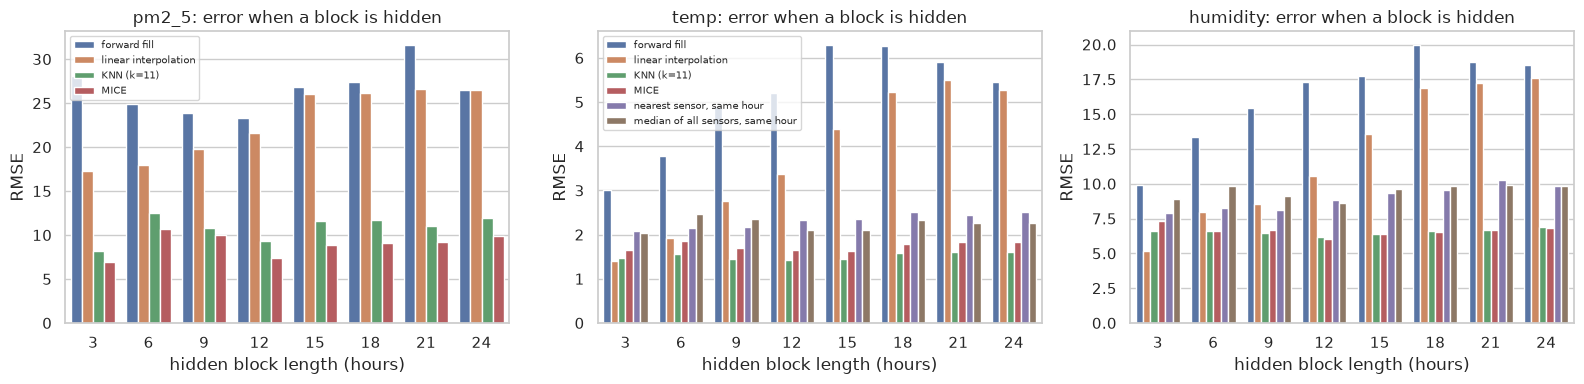

In [15]:
# same picture as a chart
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["pm2_5", "temp", "humidity"]):
    sub = benchmark[benchmark["variable"] == col]
    sns.barplot(data=sub, x="gap_hours", y="RMSE", hue="method", ax=ax)
    ax.set_title(f"{col}: error when a block is hidden")
    ax.set_xlabel("hidden block length (hours)")
axes[1].legend(fontsize=7)
axes[0].legend(fontsize=7)
axes[2].legend().remove()
plt.tight_layout()
save_fig("imputation_benchmark")

The decision cell below picks the best method from
the table

In [16]:
def best_method(variable, hours, allowed):
    sub = benchmark[(benchmark["variable"] == variable) & (benchmark["gap_hours"] == hours) & (benchmark["method"].isin(allowed))]
    return sub.sort_values("RMSE").iloc[0]

# short gaps (less than or equal to 3 hours)
SHORT_GAP_HOURS = 3
short_choice = {}
print("=== Short Gaps ===")
for col in ["pm2_5", "temp", "humidity"]:
    # Query the best simple method using the actual 3-hour benchmark results
    row = best_method(col, SHORT_GAP_HOURS, ["forward fill", "linear interpolation"])
    short_choice[col] = row["method"]
    print(f"{col:9s} gaps <= {SHORT_GAP_HOURS} h -> {row['method']:22s} | RMSE: {row['RMSE']:.2f} | MAE: {row['MAE']:.2f}")

# long gaps and sensors with no temp / humidity at all: use the other sensors
print("\n=== Long Gaps based on lowest RMSE ===")
for col in ["temp", "humidity"]:
    for h in [12, 24]:
        row = best_method(col, h, ["nearest sensor, same hour", "median of all sensors, same hour", "KNN (k=11)", "MICE"])
        print(f"{col:9s} {h:2d} h hidden -> best is {row['method']:32s} | RMSE: {row['RMSE']:.2f} | MAE: {row['MAE']:.2f}")

# --- DIRECT MAE HEAD-TO-HEAD FOR ML METHODS ---
print("\n=== ADVANCED ML COMPARISON: MAE SCORE CARD FOR LONG GAPS ===")
for col in ["temp", "humidity"]:
    for h in [12, 24]:
        print(f"\n{col.upper()} ({h}h gap) absolute errors:")
        for ml_method in ["KNN (k=11)", "MICE"]:
            # Query the benchmark score for this specific algorithm combination
            match = benchmark[
                (benchmark["variable"] == col) & 
                (benchmark["gap_hours"] == h) & 
                (benchmark["method"] == ml_method)
            ]
            if not match.empty:
                score_row = match.iloc[0]
                print(f"  -> {ml_method:12s} MAE: {score_row['MAE']:.2f} (RMSE: {score_row['RMSE']:.2f})")


=== Short Gaps ===
pm2_5     gaps <= 3 h -> linear interpolation   | RMSE: 17.28 | MAE: 9.25
temp      gaps <= 3 h -> linear interpolation   | RMSE: 1.41 | MAE: 0.96
humidity  gaps <= 3 h -> linear interpolation   | RMSE: 5.19 | MAE: 3.48

=== Long Gaps based on lowest RMSE ===
temp      12 h hidden -> best is KNN (k=11)                       | RMSE: 1.43 | MAE: 1.02
temp      24 h hidden -> best is KNN (k=11)                       | RMSE: 1.60 | MAE: 1.13
humidity  12 h hidden -> best is MICE                             | RMSE: 6.06 | MAE: 4.68
humidity  24 h hidden -> best is MICE                             | RMSE: 6.85 | MAE: 5.08

=== ADVANCED ML COMPARISON: MAE SCORE CARD FOR LONG GAPS ===

TEMP (12h gap) absolute errors:
  -> KNN (k=11)   MAE: 1.02 (RMSE: 1.43)
  -> MICE         MAE: 1.25 (RMSE: 1.65)

TEMP (24h gap) absolute errors:
  -> KNN (k=11)   MAE: 1.13 (RMSE: 1.60)
  -> MICE         MAE: 1.32 (RMSE: 1.82)

HUMIDITY (12h gap) absolute errors:
  -> KNN (k=11)   MAE: 4.50 

j_Imputation rules (and why)

| Variable | Rule | Why |
|---|---|---|
| **PM2.5** (this is the target) | fill only gaps of up to 3 hours that sit inside a window, using the winner of the table above. Rows with a still-missing PM2.5 are simply not used for training, and the loss is counted below. |
| **temp, humidity** (predictors) | gaps up to 3 h: simple method from the table. Everything else (long gaps, and the 9 sensors that never report temp/humidity): **same hour, nearest sensor**, and if nobody nearby has a value, the median of all sensors at that hour | weather is smooth in space [4], and predictors that stay missing would force me to drop whole sensors. The benchmark above tells me how much error this adds. |
| **PM10** | not imputed, and not used as a predictor | PM10 is not known in the future, and it follows PM2.5 too closely (it would leak the answer). It is only used inside the KNN/MICE test above and for the outlier check. |
| **latitude / longitude** | one median location per sensor (done in step 4) | GPS jitter |
| **hours outside the three windows** | left missing | not sampled; imputing them would be inventing data |

Every filled value is flagged (`pm2_5_imputed`, `temp_imputed`, `humidity_imputed`), and **model scores are computed on real PM2.5 readings only**.

In [17]:
def fill_short_gaps(series, max_gap, how):
    """fill runs of missing values that are at most `max_gap` long. longer runs are left alone (not even partly filled)."""
    is_missing = series.isna()
    run_id = (~is_missing).cumsum()                         # every observed value starts a new id; the NaNs after it share it
    run_length = is_missing.groupby(run_id).transform("sum")
    short = is_missing & (run_length <= max_gap)
    if how == "forward fill":
        candidate = series.ffill()
    else:
        candidate = series.interpolate(method="linear", limit_area="inside")
    return series.where(~short, candidate)

original = burst_data[["pm2_5", "temp", "humidity"]].copy()

# step A: short gaps, one (sensor, window) series at a time so nothing leaks across windows
for col in ["pm2_5", "temp", "humidity"]:
    how = short_choice[col]
    burst_data[col] = burst_data.groupby(["device_name", "burst"])[col].transform(lambda s: fill_short_gaps(s, SHORT_GAP_HOURS, how))

after_short = burst_data[["pm2_5", "temp", "humidity"]].copy()

# step B: temp and humidity, everything that is left -> other sensors
for col in ["temp", "humidity"]:
    burst_data[col] = fill_from_other_sensors(burst_data, col, use_nearest=True)

# flags + summary table
for col in ["pm2_5", "temp", "humidity"]:
    burst_data[f"{col}_imputed"] = original[col].isna() & burst_data[col].notna()

summary = pd.DataFrame({
    "real readings": [original[c].notna().sum() for c in ["pm2_5", "temp", "humidity"]],
    f"filled (gap <= {SHORT_GAP_HOURS} h)": [(original[c].isna() & after_short[c].notna()).sum() for c in ["pm2_5", "temp", "humidity"]],
    "filled from other sensors": [(after_short[c].isna() & burst_data[c].notna()).sum() for c in ["pm2_5", "temp", "humidity"]],
    "still missing": [burst_data[c].isna().sum() for c in ["pm2_5", "temp", "humidity"]],
}, index=["pm2_5", "temp", "humidity"])
summary["total hours in windows"] = summary.sum(axis=1)
summary

,real readings,filled (gap <= 3 h),filled from other sensors,still missing,total hours in windows
pm2_5,14272,806,0,6825,21903
temp,10480,576,10847,0,21903
humidity,10235,585,11083,0,21903


k_Feature selection

| Column | Used? | Reason |
|---|---|---|
| `hour_sin`, `hour_cos` | yes | PM2.5 has a clear daily rhythm with peaks around 04:00-05:00 and 17:00-18:00 in Kampala [2]; known in the future |
| `temp`, `humidity` | yes | the brief and [2] say they matter for PM2.5 (temperature through the boundary layer, humidity through particle growth); in [2] meteorology explained roughly 18% of PM2.5 variation in Kampala, so I expect a small effect |
| `latitude`, `longitude` | yes | pollution differs by place (traffic, burning, dust); a cheap way to tell the model *which* sensor it is looking at |
| `pm10` | **no** | not known in the future, and it would leak PM2.5 (same particles) |
| day of week | **no** | [2] found no weekday/weekend difference in Kampala, and we only have 9 days, so it would just memorise those days |
| month | **no** | only 3 months exist (Jan, Apr, Jun); a number like month=8 would force the model to extrapolate |
| `site_name`, `device_name`, `site_id` | **no** | identifiers; they only help to memorise a sensor and they do not exist for new sensors |
| `network`, `frequency` | **no** | `frequency` is "hourly" for every row (no information); `network` is almost always "airqo" |

In [18]:
# what do I lose? (the brief asks me to reason about this instead of silently dropping rows)
rows_total_file     = len(raw)
rows_with__file = int(raw["pm2_5_calibrated_value"].replace(0, np.nan).notna().sum())
rows__now       = int(burst_data["pm2_5"].notna().sum())
print(f"rows in the csv:                              {rows_total_file}")
print(f"rows with a PM2.5 value in the csv:           {rows_with__file}")
print(f"PM2.5 values after cleaning and short fills:  {rows__now}")
print(f"   of which filled by imputation:             {int(burst_data['pm2_5_imputed'].sum())}")
print(f"   removed as impossible (>500):              {outlier_log[0]['rows']}")
print(f"hours inside the windows with no PM2.5 (not used for training): {int(burst_data['pm2_5'].isna().sum())}")

# save the full hourly grid and the working table
for col in ["pm2_5", "temp", "humidity"]:
    data.loc[data["in_burst"], col] = burst_data[col].to_numpy()
data.to_csv(f"{OUT_DIR}/clean_hourly_grid.csv.gz", index=False)
burst_data.to_csv(f"{OUT_DIR}/clean_burst_data.csv.gz", index=False)
print("saved clean tables to", OUT_DIR)

rows in the csv:                              14600
rows with a PM2.5 value in the csv:           14275
PM2.5 values after cleaning and short fills:  15078
   of which filled by imputation:             806
   removed as impossible (>500):              3
hours inside the windows with no PM2.5 (not used for training): 6825
saved clean tables to outputs


##2 Exploratory data analysis
a_Choosing 5 Kampala sensors

We pick sensors that really sit in Kampala (GPS box around the city), have almost complete PM2.5 and their own temperature/humidity, and are also spread over different parts of the city.

In [19]:
# rough box around Kampala (latitude 0.20 to 0.45 N, longitude 32.45 to 32.70 E)
in_kampala = (device_info["latitude"].between(0.20, 0.45)) & (device_info["longitude"].between(32.45, 32.70)) & (~device_info["coords_guessed"])

# real readings only (before filling) so I do not pick a sensor because of imputed data
real_counts = pd.DataFrame({
    "pm2_5_hours": original["pm2_5"].notna().groupby(burst_data["device_name"]).sum(),
    "temp_hours": original["temp"].notna().groupby(burst_data["device_name"]).sum(),
})
candidates = device_info[in_kampala].set_index("device_name").join(real_counts).sort_values("pm2_5_hours", ascending=False)
print("sensors inside the Kampala box:", len(candidates))
print(candidates[["site_name", "latitude", "longitude", "pm2_5_hours", "temp_hours"]].head(12).round(3).to_string())

sensors inside the Kampala box: 95
                                              site_name  latitude  longitude  pm2_5_hours  temp_hours
device_name                                                                                          
aq_66                           Nakasero II, Kampala 66     0.322     32.576          147         147
aq_g5_37                  Civic Centre, Kampala Central     0.319     32.590          147         147
aq_58                         Nansana east ward, Wakiso     0.376     32.528          145         145
aq_47                                 Bukoto I, Kawempe     0.352     32.591          145          67
aq_g507                           Lower Nsooba, Kawempe     0.350     32.576          144         144
airqo_g5341      Makerere University Weather Station 94     0.334     32.569          142         143
ag_588c81267534                             Salama Road     0.334     32.569          142         142
aq_g5_54                           KCCA Divisio

The top of that list is crowded in the centre, so we choose one very complete sensor from five different areas of the city.

In [20]:
eda_sensors = {
    "aq_g5_37":        "Central (Civic Centre)",
    "aq_g507":         "North (Lower Nsooba, Kawempe)",
    "aq_g5_101":       "South-east (Water & Environment House, Luzira)",
    "airqo_g5365":     "North-west (Namungona P.S.)",
    "ag_588c81267534": "South (Salama Road)",
}
eda_ids = list(eda_sensors.keys())
eda_table = candidates.loc[eda_ids, ["site_name", "latitude", "longitude", "pm2_5_hours", "temp_hours"]].copy()
eda_table["zone"] = pd.Series(eda_sensors)
print(eda_table.round(3).to_string())
print("\nmax possible hours per sensor inside the windows:", burst_data.groupby("device_name").size().iloc[0])

eda = burst_data[burst_data["device_name"].isin(eda_ids)].copy()
eda["zone"] = eda["device_name"].map(eda_sensors)
sensor_colour = dict(zip(eda_ids, sns.color_palette("tab10", 5)))

                                           site_name  latitude  longitude  pm2_5_hours  temp_hours                                            zone
device_name                                                                                                                                       
aq_g5_37               Civic Centre, Kampala Central     0.319     32.590          147         147                          Central (Civic Centre)
aq_g507                        Lower Nsooba, Kawempe     0.350     32.576          144         144                   North (Lower Nsooba, Kawempe)
aq_g5_101        Water and Environment House, Luzira     0.298     32.650          134         135  South-east (Water & Environment House, Luzira)
airqo_g5365                 Namungona Primary school     0.326     32.538          135         140                     North-west (Namungona P.S.)
ag_588c81267534                          Salama Road     0.334     32.569          142         142                    

b_Distribution and box plots

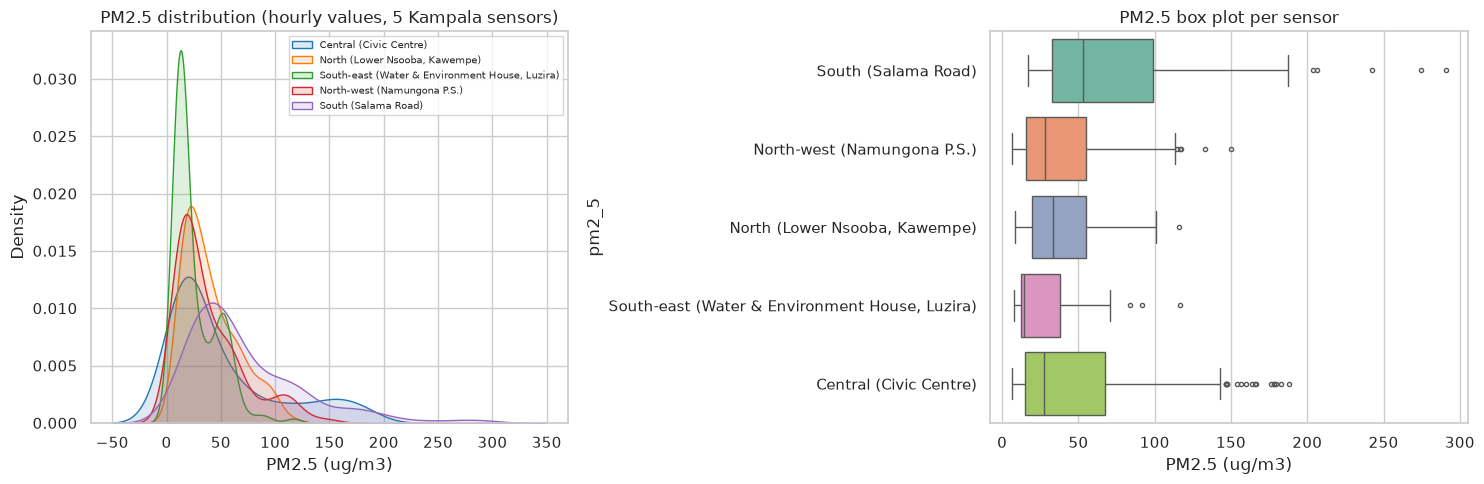

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for dev in eda_ids:
    sns.kdeplot(eda.loc[eda["device_name"] == dev, "pm2_5"].dropna(), ax=axes[0], label=eda_sensors[dev], color=sensor_colour[dev], fill=True, alpha=0.15)
axes[0].set_title("PM2.5 distribution (hourly values, 5 Kampala sensors)")
axes[0].set_xlabel("PM2.5 (ug/m3)")
axes[0].legend(fontsize=7)

sns.boxplot(data=eda, y="zone", x="pm2_5", ax=axes[1], hue="zone", palette="Set2", legend=False, fliersize=3)
axes[1].set_title("PM2.5 box plot per sensor")
axes[1].set_xlabel("PM2.5 (ug/m3)")
axes[1].set_ylabel("pm2_5")
plt.tight_layout()
save_fig("eda__distribution_box")

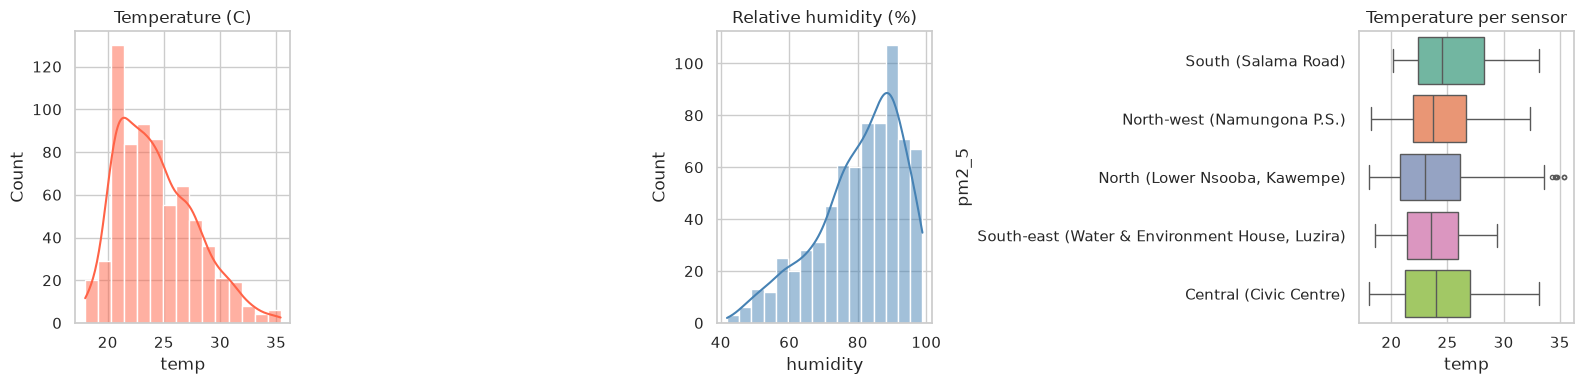

In [22]:
# other relevant fields: temperature and humidity (only real readings, not the filled ones)
real_weather = eda[~eda["temp_imputed"] & ~eda["humidity_imputed"]]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(real_weather["temp"].dropna(), kde=True, ax=axes[0], color="tomato")
axes[0].set_title("Temperature (C)")
sns.histplot(real_weather["humidity"].dropna(), kde=True, ax=axes[1], color="steelblue")
axes[1].set_title("Relative humidity (%)")
sns.boxplot(data=real_weather, y="zone", x="temp", ax=axes[2], hue="zone", palette="Set2", legend=False, fliersize=3)
axes[2].set_title("Temperature per sensor")
axes[2].set_ylabel("pm2_5")
plt.tight_layout()
save_fig("eda_temp_humidity_distribution")

In [23]:
# outlier tracking table for these 5 sensors (flag = above the sensor's own Q3 + 1.5*IQR)
rows = []
for dev in eda_ids:
    values = eda.loc[eda["device_name"] == dev, "pm2_5"].dropna()
    q1, q3 = values.quantile(0.25), values.quantile(0.75)
    upper = q3 + 1.5 * (q3 - q1)
    rows.append({"sensor": eda_sensors[dev], "readings": len(values), "Q1": q1, "Q3": q3, "upper fence": upper,
                 "flagged": int((values > upper).sum()), "% flagged": 100 * (values > upper).mean(),
                 "max": values.max(), "treatment": "kept (real episodes, see step 5)"})
outlier_table = pd.DataFrame(rows).round(1)
outlier_table.to_csv(f"{OUT_DIR}/outlier_tracking_eda_sensors.csv", index=False)
print(outlier_table.to_string(index=False))

                                        sensor  readings   Q1   Q3  upper fence  flagged  % flagged   max                        treatment
                        Central (Civic Centre)       147 15.2 67.4        145.8       17       11.6 188.2 kept (real episodes, see step 5)
                 North (Lower Nsooba, Kawempe)       147 19.6 54.7        107.3        1        0.7 115.9 kept (real episodes, see step 5)
South-east (Water & Environment House, Luzira)       139 12.1 37.9         76.7        3        2.2 116.8 kept (real episodes, see step 5)
                   North-west (Namungona P.S.)       137 15.4 55.0        114.3        5        3.6 149.8 kept (real episodes, see step 5)
                           South (Salama Road)       144 32.8 98.7        197.5        5        3.5 291.0 kept (real episodes, see step 5)


c_Time series with AQI bands

Coloured stripes are the AQI bands and red crosses are the flagged IQR outliers.

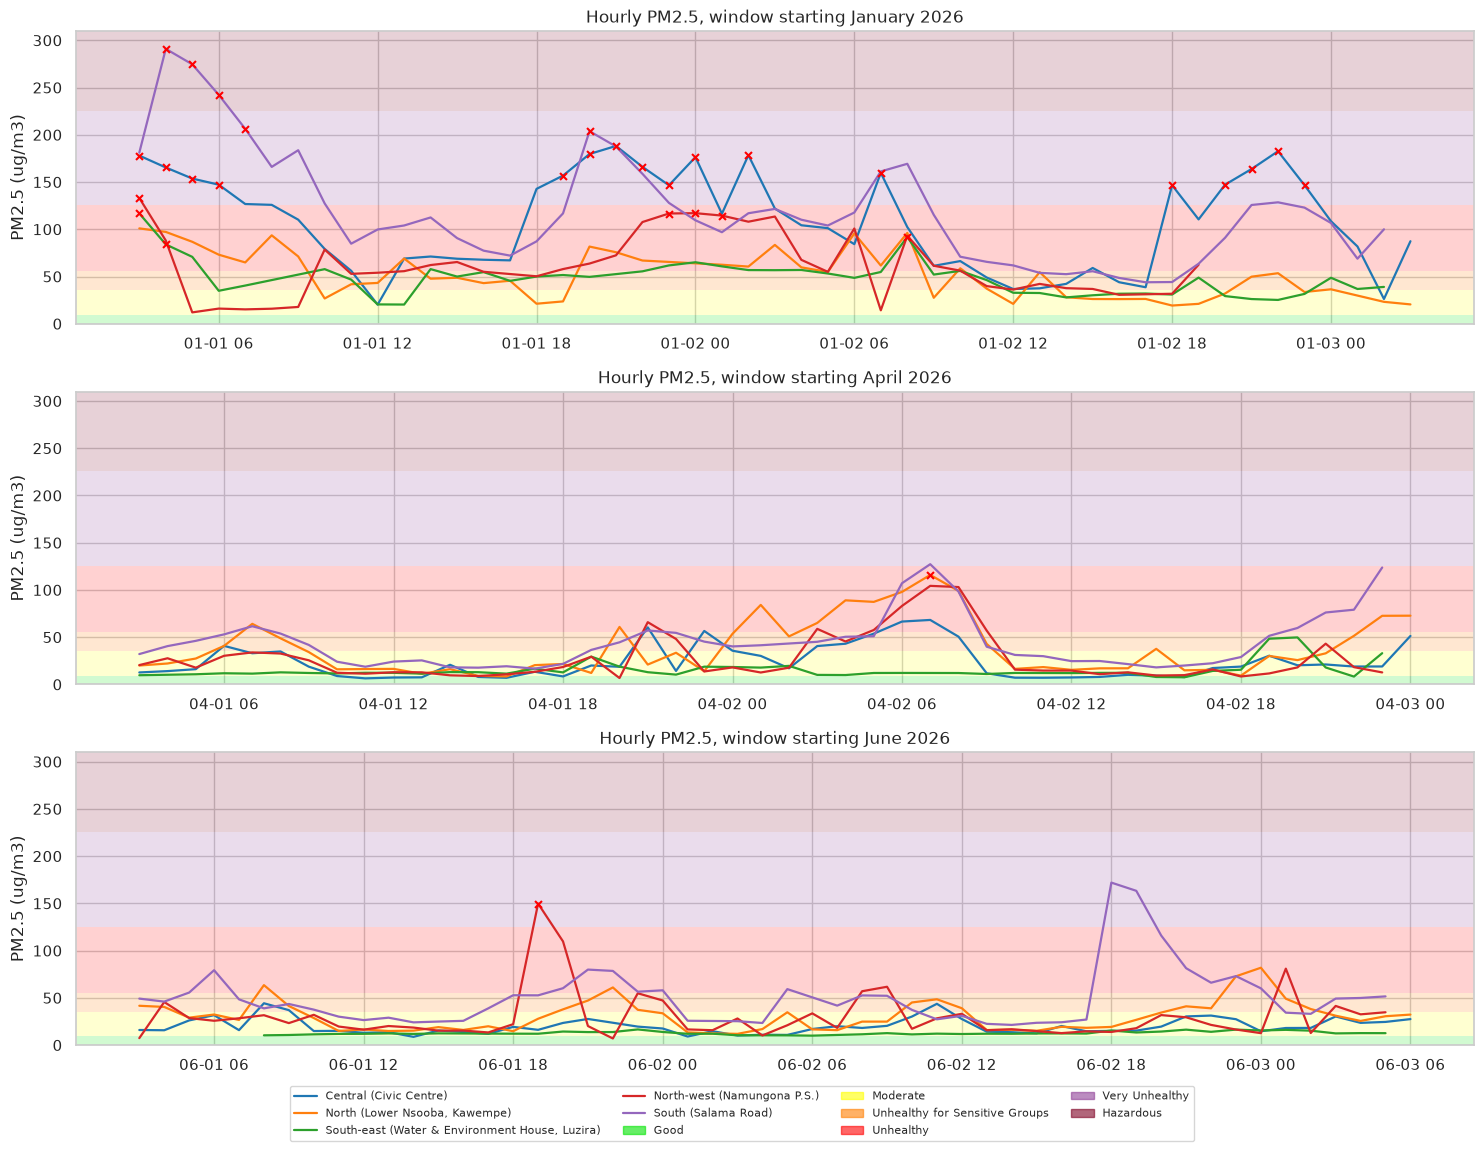

In [24]:
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharey=True)
y_top = np.ceil(eda["pm2_5"].max() / 25) * 25 + 10
for ax, win in zip(axes, [1, 4, 6]):
    add_aqi_bands(ax, y_top)
    part = eda[eda["burst"] == win]
    for dev in eda_ids:
        one = part[part["device_name"] == dev].sort_values("datetime")
        ax.plot(one["datetime"], one["pm2_5"], lw=1.6, color=sensor_colour[dev], label=eda_sensors[dev])
        upper = outlier_table.loc[outlier_table["sensor"] == eda_sensors[dev], "upper fence"].iloc[0]
        spikes = one[one["pm2_5"] > upper]
        ax.scatter(spikes["datetime"], spikes["pm2_5"], marker="x", color="red", s=25, zorder=5)
    ax.set_title(f"Hourly PM2.5, window starting {calendar.month_name[win]} 2026")
    ax.set_ylabel("PM2.5 (ug/m3)")
sensor_handles, _ = axes[0].get_legend_handles_labels()
fig.legend(handles=sensor_handles + aqi_legend_handles(), loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.05))
plt.tight_layout()
save_fig("eda_timeseries_aqi_bands")

d_Calendar plots (unscaled, cleaned PM2.5, coloured by AQI category)

Each box is one day's average PM2.5 for one sensor. A daily average is only calculated when at least 18 of the 24 hours exist
(75% completeness, the usual rule for reporting daily air-quality averages)

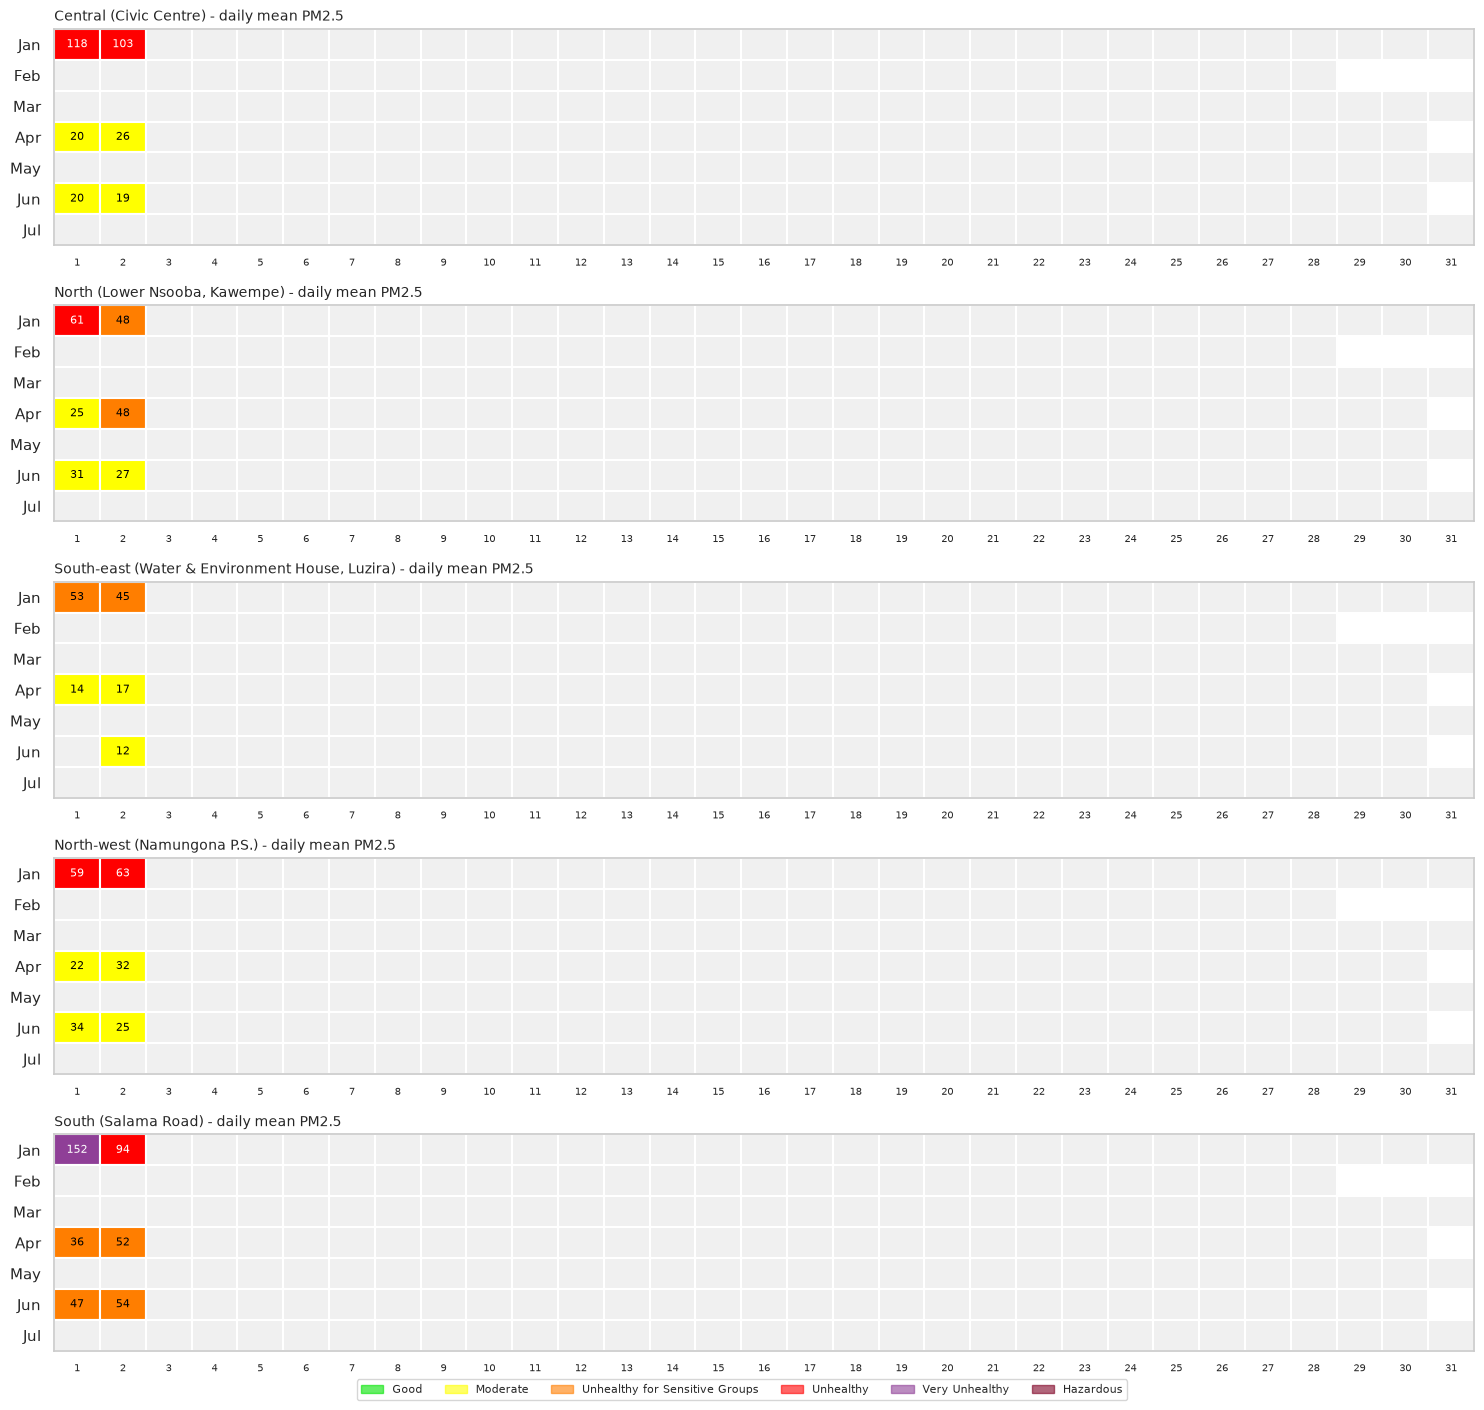

In [25]:
def daily_means(frame, col, min_hours=18):
    """one row per (sensor, day): mean of the hourly values, only when the day has enough hours"""
    tmp = frame.dropna(subset=[col]).copy()
    tmp["date"] = tmp["datetime"].dt.tz_localize(None).dt.normalize()
    out = tmp.groupby(["device_name", "date"])[col].agg(["mean", "count"]).reset_index()
    return out[out["count"] >= min_hours]

def calendar_plot(ax, daily, months, title, year=2026):
    """daily = Series indexed by date. draws one box per day, coloured by AQI band, with the value written inside"""
    lookup = {(d.month, d.day): v for d, v in daily.items()}
    for row, month in enumerate(months):
        for day in range(1, calendar.monthrange(year, month)[1] + 1):
            value = lookup.get((month, day))
            if value is None or np.isnan(value):
                face, text, text_colour = "#f0f0f0", "", "black"
            else:
                band = int(aqi_category([value]).codes[0])
                face, text = AQI_COLOURS[band], f"{value:.0f}"
                text_colour = "white" if band >= 3 else "black"
            ax.add_patch(mpatches.Rectangle((day - 1, row), 1, 1, facecolor=face, edgecolor="white", lw=1.5))
            if text:
                ax.text(day - 0.5, row + 0.5, text, ha="center", va="center", fontsize=8, color=text_colour)
    ax.set_xlim(0, 31)
    ax.set_ylim(len(months), 0)
    ax.set_xticks(np.arange(31) + 0.5)
    ax.set_xticklabels(range(1, 32), fontsize=7)
    ax.set_yticks(np.arange(len(months)) + 0.5)
    ax.set_yticklabels([calendar.month_abbr[m] for m in months])
    ax.set_title(title, fontsize=10, loc="left")
    ax.grid(False)

eda_daily = daily_means(eda, "pm2_5")
fig, axes = plt.subplots(5, 1, figsize=(15, 14))
for ax, dev in zip(axes, eda_ids):
    daily = eda_daily[eda_daily["device_name"] == dev].set_index("date")["mean"]
    calendar_plot(ax, daily, months=range(1, 8), title=f"{eda_sensors[dev]} - daily mean PM2.5")
fig.legend(handles=aqi_legend_handles(), loc="lower center", ncol=6, fontsize=8, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout()
save_fig("eda_calendar_daily_")

e_Z-score transformation (all sensors)

"how many standard deviations above or below the usual level".
We calculate $\mu$ and $\sigma$ from the only from the training windows(January and April) over all sensors and then apply the
same two numbers to every sensor and every window.

mean (mu) = 36.74 ug/m3   std (sigma) = 29.35 ug/m3   (from 9919 training readings, all sensors)

z-scores by window (train windows should be ~0 mean and ~1 std):
                mean   std  count
January window  0.40  1.05   5168
April window   -0.43  0.73   4751
June window    -0.42  0.76   5159

AQI limits written as z-scores (upper limit of each band):
                                AQI limit (ug/m3)  same limit as z-score
Good                                         9.10                  -0.94
Moderate                                    35.49                  -0.04
Unhealthy for Sensitive Groups              55.49                   0.64
Unhealthy                                  125.49                   3.02
Very Unhealthy                             225.49                   6.43


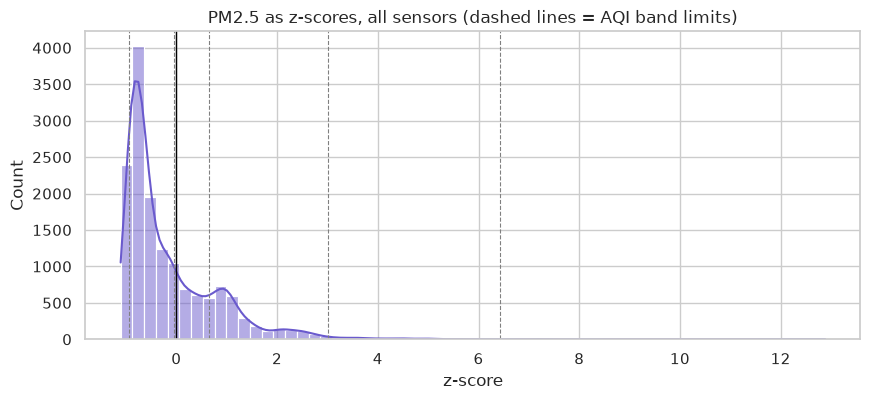

In [26]:
train_ = burst_data.loc[burst_data["burst"].isin([1, 4]), "pm2_5"].dropna()
MU, SD = train_.mean(), train_.std()
burst_data["pm2_5_z"] = (burst_data["pm2_5"] - MU) / SD
print(f"mean (mu) = {MU:.2f} ug/m3   std (sigma) = {SD:.2f} ug/m3   (from {len(train_)} training readings, all sensors)")

check = burst_data.groupby("burst")["pm2_5_z"].agg(["mean", "std", "count"]).round(2)
check.index = ["January window", "April window", "June window"]
print("\nz-scores by window (train windows should be ~0 mean and ~1 std):")
print(check)

aqi_in_z = pd.DataFrame({"AQI limit (ug/m3)": [9.1, 35.49, 55.49, 125.49, 225.49]}, index=AQI_NAMES[:5])
aqi_in_z["same limit as z-score"] = ((aqi_in_z["AQI limit (ug/m3)"] - MU) / SD).round(2)
print("\nAQI limits written as z-scores (upper limit of each band):")
print(aqi_in_z)

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(burst_data["pm2_5_z"].dropna(), bins=60, kde=True, ax=ax, color="slateblue")
for limit in aqi_in_z["same limit as z-score"]:
    ax.axvline(limit, color="grey", ls="--", lw=0.8)
ax.axvline(0, color="black", lw=1)
ax.set_title("PM2.5 as z-scores, all sensors (dashed lines = AQI band limits)")
ax.set_xlabel("z-score")
save_fig("eda_zscore_distribution")

f_Temperature / humidity vs PM2.5 (the 5 Kampala sensors)

Only real temp/humidity readings are used here (no filled values), so the correlation is not influenced by imputation.
We used both Pearson (straight-line relationship) and Spearman (rank relationship, which [2] used because PM2.5 is skewed).

rows used: 698

All 5 sensors pooled - correlation with PM2.5:
          Pearson  Spearman
temp        -0.17     -0.14
humidity     0.06      0.06

temp vs humidity: Pearson = -0.89

Per sensor:
                                        sensor   n  PM2.5 vs temp (Spearman)  PM2.5 vs humidity (Spearman)
                        Central (Civic Centre) 147                     -0.09                          0.04
                 North (Lower Nsooba, Kawempe) 144                     -0.33                          0.40
South-east (Water & Environment House, Luzira) 130                      0.10                          0.00
                   North-west (Namungona P.S.) 135                     -0.23                          0.11
                           South (Salama Road) 142                     -0.56                          0.48


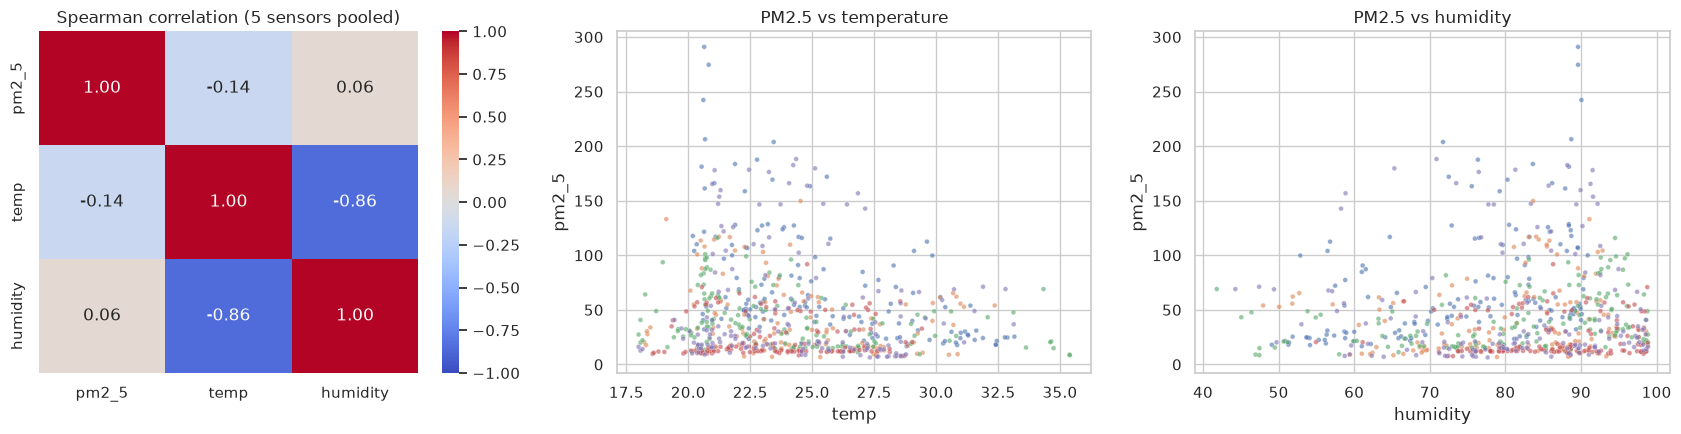

In [27]:
real_rows = eda[~eda["temp_imputed"] & ~eda["humidity_imputed"]].dropna(subset=["pm2_5", "temp", "humidity"])
print("rows used:", len(real_rows))

pooled = pd.DataFrame({
    "Pearson": real_rows[["temp", "humidity"]].corrwith(real_rows["pm2_5"], method="pearson"),
    "Spearman": real_rows[["temp", "humidity"]].corrwith(real_rows["pm2_5"], method="spearman"),
}).round(2)
print("\nAll 5 sensors pooled - correlation with PM2.5:")
print(pooled)
print("\ntemp vs humidity: Pearson =", round(real_rows["temp"].corr(real_rows["humidity"]), 2))

per_sensor = []
for dev in eda_ids:
    one = real_rows[real_rows["device_name"] == dev]
    per_sensor.append({"sensor": eda_sensors[dev], "n": len(one),
                       "PM2.5 vs temp (Spearman)": one["pm2_5"].corr(one["temp"], method="spearman"),
                       "PM2.5 vs humidity (Spearman)": one["pm2_5"].corr(one["humidity"], method="spearman")})
per_sensor = pd.DataFrame(per_sensor).round(2)
per_sensor.to_csv(f"{OUT_DIR}/correlation_per_sensor.csv", index=False)
print("\nPer sensor:")
print(per_sensor.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.heatmap(real_rows[["pm2_5", "temp", "humidity"]].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Spearman correlation (5 sensors pooled)")
sns.scatterplot(data=real_rows, x="temp", y="pm2_5", hue="zone", s=12, alpha=0.6, ax=axes[1], legend=False)
axes[1].set_title("PM2.5 vs temperature")
sns.scatterplot(data=real_rows, x="humidity", y="pm2_5", hue="zone", s=12, alpha=0.6, ax=axes[2], legend=False)
axes[2].set_title("PM2.5 vs humidity")
plt.tight_layout()
save_fig("eda_correlation_temp_humidity")

##3 Machine learning models
a_Modelling table and the train / test split
Target = `pm2_5_z` (the z-score from the EDA section).
Predictors = the six columns in the feature table(hour_sin, hour_cos, temp, humidity, latitude, longitude).

Split into three(train, validation and test). All available months are pooled and a stratified split using a combination of device_name and month is done. This guarantees that every split has representative samples from all three months.

Scoring uses real PM2.5 readings only: the hours we filled in may be used for training but never for the score.

In [28]:
import time
from sklearn.metrics import make_scorer
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.inspection import permutation_importance

FEATURES = ["hour_sin", "hour_cos", "temp", "humidity", "latitude", "longitude"]
TARGET = "pm2_5_z"

has_target   = burst_data["pm2_5"].notna()
has_features = burst_data[FEATURES].notna().all(axis=1)
print("hours inside the windows:", len(burst_data))
print("hours with a PM2.5 value (real, or filled up to 3 h):", int(has_target.sum()))
print("   dropped because a predictor is missing:", int((has_target & ~has_features).sum()))

model_table = burst_data[has_target & has_features].copy()

# Create a stratification key combining the device_name and the burst/month window
# to ensure representative splits of both geography and season (all 3 months)
model_table["stratify_key"] = model_table["device_name"].astype(str) + "_" + model_table["burst"].astype(str)

# Filter to keys that have at least 6 samples to ensure that when we split 70/30,
# the remaining 30% pool (temp_df) has at least 2 samples per key for the second stratified split.
key_counts = model_table["stratify_key"].value_counts()
valid_keys = key_counts[key_counts >= 6].index
filtered_table = model_table[model_table["stratify_key"].isin(valid_keys)].reset_index(drop=True)

# First split: Train (70%) vs Temp (30%)
train_df, temp_df = train_test_split(
    filtered_table,
    test_size=0.30,
    random_state=SEED,
    stratify=filtered_table["stratify_key"]
)

# Second split: Validation (15%) vs Test (15%)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["stratify_key"]
)

train = train_df.reset_index(drop=True)
val = val_df.reset_index(drop=True)
test = test_df[~test_df["pm2_5_imputed"]].reset_index(drop=True)  # Scored on real readings only

# Verify month representation in each split
for name, df_split in zip(["Train", "Validation", "Test (real only)"], [train, val, test]):
    months_present = sorted(df_split["burst"].unique())
    print(f"{name:18s} rows: {len(df_split):5d} | Months present: {months_present}")

X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

hours inside the windows: 21903
hours with a PM2.5 value (real, or filled up to 3 h): 15078
   dropped because a predictor is missing: 0
Train              rows: 10544 | Months present: [np.int64(1), np.int64(4), np.int64(6)]
Validation         rows:  2260 | Months present: [np.int64(1), np.int64(4), np.int64(6)]
Test (real only)   rows:  2146 | Months present: [np.int64(1), np.int64(4), np.int64(6)]


b_Evaluation metrics (and why these)
| Metric | What it tells | Why use it / when something else is better |
|---|---|---|
| **RMSE** (ug/m3) | typical error, big misses count more | the main metric: missing an unhealthy spike is the costly mistake for health warnings |
| **MAE** (ug/m3) | average miss in plain units | easy to explain to a non-technical reader; better than RMSE if a few sensor glitches should not dominate |
| **R2** | share of the variation explained (0 = no better than the average, negative = worse) | good to compare models, but misleading when the test period looks different from training |
| **bias** (ug/m3) | average prediction minus average truth | separates "the whole window is predicted too high or low" from "the pattern is wrong" |
| **centred RMSE** (ug/m3) | RMSE after removing the bias | measures only the *pattern*: are the right hours and places higher? |
| **AQI accuracy** | share of hours put in the correct AQI colour band | what a health officer actually acts on |
| **alert recall** | of the hours that were really above 35.49 ug/m3 (USG or worse), how many did I flag | a missed warning is worse than a false alarm |

In [29]:
def to_ugm3(z):
    """z-score back to ug/m3 (the inverse of the Z-score transformation)"""
    return np.asarray(z, dtype=float) * SD + MU

def centred_rmse(y_true, y_pred):
    """RMSE after removing the average level of both series, so only the pattern is judged"""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return float(np.sqrt(np.mean(((y_pred - y_pred.mean()) - (y_true - y_true.mean())) ** 2)))

def scores(y_true_z, y_pred_z):
    true_ug = to_ugm3(y_true_z)
    pred_ug = np.clip(to_ugm3(y_pred_z), 0, None)               # a concentration cannot be negative
    rmse = float(np.sqrt(mean_squared_error(true_ug, pred_ug)))
    bias = float(np.mean(pred_ug - true_ug))
    really_unhealthy, flagged = true_ug > 35.49, pred_ug > 35.49
    return {
        "RMSE": rmse,
        "MAE": float(mean_absolute_error(true_ug, pred_ug)),
        "R2": float(r2_score(true_ug, pred_ug)),
        "bias": bias,
        "centred RMSE": float(np.sqrt(max(rmse ** 2 - bias ** 2, 0))),
        "AQI accuracy": float((aqi_category(true_ug).codes == aqi_category(pred_ug).codes).mean()),
        "alert recall": float((really_unhealthy & flagged).sum() / max(really_unhealthy.sum(), 1)),
    }

c_Baselines (the bar every model has to beat)

In [30]:
global_mean = train["pm2_5"].mean()
mean_by_hour = train.groupby("hour")["pm2_5"].mean()
mean_by_sensor = train.groupby("device_name")["pm2_5"].mean()

# Evaluate Baselines on Validation Split
baseline_val_ug = {
    "global mean": np.full(len(val), global_mean),
    "mean of that hour": val["hour"].map(mean_by_hour).fillna(global_mean).to_numpy(),
    "mean of that sensor": val["device_name"].map(mean_by_sensor).fillna(global_mean).to_numpy(),
}
baselines_val = pd.DataFrame({name: scores(y_val, (pred - MU) / SD) for name, pred in baseline_val_ug.items()}).T
print("=== Baselines on Validation Split ===")
display(baselines_val.round(3))

# Evaluate Baselines on Test Split
baseline_test_ug = {
    "global mean": np.full(len(test), global_mean),
    "mean of that hour": test["hour"].map(mean_by_hour).fillna(global_mean).to_numpy(),
    "mean of that sensor": test["device_name"].map(mean_by_sensor).fillna(global_mean).to_numpy(),
}
baselines = pd.DataFrame({name: scores(y_test, (pred - MU) / SD) for name, pred in baseline_test_ug.items()}).T
print("\n=== Baselines on Test Split ===")
display(baselines.round(3))

=== Baselines on Validation Split ===


,RMSE,MAE,R2,bias,centred RMSE,AQI accuracy,alert recall
global mean,26.175,20.706,-0.001,0.797,26.162,0.585,0.000
mean of that hour,25.168,19.545,0.075,0.597,25.161,0.451,0.476
mean of that sensor,23.499,17.777,0.193,0.752,23.487,0.523,0.497



=== Baselines on Test Split ===


,RMSE,MAE,R2,bias,centred RMSE,AQI accuracy,alert recall
global mean,27.461,20.804,-0.000,0.389,27.458,0.593,0.000
mean of that hour,26.584,19.777,0.063,0.163,26.583,0.461,0.470
mean of that sensor,24.985,18.018,0.172,0.444,24.981,0.528,0.508


d_Leave-One-Group-Out on Train

We tune models on our training split using Leave-One-Group-Out cross-validation to ensure that we capture temporal patterns robustly.

In [31]:
# Keep Leave-One-Group-Out CV on the train set for robust hyperparameter tuning
groups = train["burst"]
logo_splits = list(LeaveOneGroupOut().split(X_train, y_train, groups))
for k, (a, b) in enumerate(logo_splits, 1):
    print(f"fold {k}: train on window {sorted(groups.iloc[a].unique())} ({len(a)} rows) -> validate on window {sorted(groups.iloc[b].unique())} ({len(b)} rows)")

cv_scorer = make_scorer(centred_rmse, greater_is_better=False)

fold 1: train on window [np.int64(4), np.int64(6)] (6927 rows) -> validate on window [np.int64(1)] (3617 rows)
fold 2: train on window [np.int64(1), np.int64(6)] (7219 rows) -> validate on window [np.int64(4)] (3325 rows)
fold 3: train on window [np.int64(1), np.int64(4)] (6942 rows) -> validate on window [np.int64(6)] (3602 rows)


e_The five models and what we tune
| Model | Hyper-parameters tuned | Why they matter for this model |
|---|---|---|
| **Ridge regression** | `alpha` | the strength of the penalty on large coefficients. Too small = the line follows noise, too large = the line goes flat |
| **K-nearest neighbours** | `n_neighbors`, `weights` | k = how many similar hours/places are averaged (small k is noisy, large k is smooth). `distance` weights trust closer neighbours more. Features are scaled first because KNN works with distances |
| **Decision tree** | `max_depth`, `min_samples_leaf` | they limit how detailed the tree can get. Without a limit it memorises single hours |
| **Random forest** | `max_depth`, `min_samples_leaf`, `max_features` | depth and leaf size limit each tree; `max_features` makes the trees look at different columns so their mistakes differ, and averaging them cancels noise |
| **Gradient boosting** | `n_estimators`, `learning_rate`, `max_depth`, `subsample` | trees are added one by one to fix the previous errors. A small learning rate with more trees is safer, shallow trees and `subsample` < 1 reduce over-fitting |
| **Histogram gradient boosting** (extra) | `learning_rate`, `max_depth`, `min_samples_leaf`, `l2_regularization`; `max_iter` is chosen by **early stopping** on an internal 15% validation split | same idea as gradient boosting but bins the features (fast) and learns where missing values should go at every split, which the group agreed the deployed model needs. Early stopping picks the number of trees, so it is not grid-searched |

We use a grid search scored with the centred RMSE.
Ridge and KNN have a `StandardScaler` inside the pipeline, so the scaling is learned only on the training fold.

In [ ]:
model_setups = {
    "Ridge": (
        make_pipeline(StandardScaler(), Ridge()),
        {"ridge__alpha": [0.1, 1, 10, 100, 1000, 10000]}
    ),
    "KNN": (
        make_pipeline(StandardScaler(), KNeighborsRegressor()),
        {
            "kneighborsregressor__n_neighbors": [10, 25, 50, 100],
            "kneighborsregressor__weights": ["uniform", "distance"]
        }
    ),
    "Decision Tree": (
        DecisionTreeRegressor(random_state=SEED),
        {
            "max_depth": [3, 5, 8, 12, None],
            "min_samples_leaf": [5, 10, 30, 60],
            "min_samples_split": [2, 10, 30]
        }
    ),
    "Random Forest": (
        RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1),
        {
            "max_depth": [6, 12, 20, None],
            "min_samples_leaf": [2, 5, 20, 50],
            "max_features": [0.3, 0.5, 1.0]
        }
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=SEED),
        {
            "n_estimators": [150, 300],
            "learning_rate": [0.01, 0.03, 0.1],
            "max_depth": [3, 5, 7],
            "subsample": [0.7, 0.85, 1.0],
            "min_samples_leaf": [10, 30]
        }
    ),
    "Hist Gradient Boosting": (
        HistGradientBoostingRegressor(
            max_iter=500, 
            early_stopping=True, 
            validation_fraction=0.15,
            n_iter_no_change=20, 
            random_state=SEED
        ),
        {
            "learning_rate": [0.01, 0.03, 0.1],
            "max_depth": [3, 6, None],
            "max_leaf_nodes": [15, 31, 63],
            "min_samples_leaf": [10, 20, 50],
            "l2_regularization": [0.0, 0.1, 1.0, 10.0]
        }
    ),
    "LightGBM": (
        LGBMRegressor(random_state=SEED, n_jobs=1, verbose=-1),
        {
            "n_estimators": [1000],
            "learning_rate": [0.01, 0.03, 0.1],
            "max_depth": [-1, 4, 8],
            "num_leaves": [15, 31, 63],
            "min_child_samples": [10, 20, 50],
            "subsample": [0.7, 1.0],
            "colsample_bytree": [0.7, 1.0],
            "reg_alpha": [0.0, 1.0],
            "reg_lambda": [0.0, 1.0]
        }
    ),
}

searches, result_rows = {}, []
for name, (model, param_grid) in model_setups.items():
    start = time.time()
    search = GridSearchCV(model, param_grid, scoring=cv_scorer, cv=logo_splits, n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    searches[name] = search

    row = {"model": name, "CV centred RMSE": -search.best_score_ * SD}
    # Score on Validation set to assess tuning performance
    val_predictions = search.best_estimator_.predict(X_val)
    row.update({f"val_{k}": v for k, v in scores(y_val, val_predictions).items()})
    # Score on Test set for final reports
    row.update(scores(y_test, search.best_estimator_.predict(X_test)))
    row["seconds"] = round(time.time() - start, 1)
    result_rows.append(row)
    settings = {k.split("__")[-1]: v for k, v in search.best_params_.items()}
    print(f"{name:18s} CV centred RMSE = {row['CV centred RMSE']:5.2f} | test RMSE = {row['RMSE']:5.2f} | best settings: {settings}")

Ridge              CV centred RMSE = 24.68 | test RMSE = 26.38 | best settings: {'alpha': 1000}
KNN                CV centred RMSE = 25.00 | test RMSE = 25.24 | best settings: {'n_neighbors': 100, 'weights': 'uniform'}
Decision Tree      CV centred RMSE = 25.05 | test RMSE = 25.58 | best settings: {'max_depth': 5, 'min_samples_leaf': 100}
Random Forest      CV centred RMSE = 24.50 | test RMSE = 25.69 | best settings: {'max_depth': 4, 'max_features': 0.5, 'min_samples_leaf': 50}
Gradient Boosting  CV centred RMSE = 24.43 | test RMSE = 25.36 | best settings: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 250, 'subsample': 1.0}
Hist Gradient Boosting CV centred RMSE = 25.04 | test RMSE = 23.88 | best settings: {'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_depth': 3, 'min_samples_leaf': 20}
LightGBM           CV centred RMSE = 24.90 | test RMSE = 23.56 | best settings: {'colsample_bytree': 0.7, 'learning_rate': 0.01, 'max_depth': 4, 'min_child_samples': 10, 'n_estimators'

f_Ensemble: weighted average of the tuned Random Forest, Gradient Boosting and KNN

The three tuned models make different kinds of mistakes (two tree ensembles and one distance-based model), so averaging them can cancel
some of the errors. The hyper-parameter we tune here is the **weight** of each member.

In [53]:
# --- 1. First Ensemble: Mid-Tier Models (RF, GB, KNN) ---
start = time.time()

voting = VotingRegressor([
    ("rf",  clone(searches["Random Forest"].best_estimator_)),
    ("gb",  clone(searches["Gradient Boosting"].best_estimator_)),
    ("knn", clone(searches["KNN"].best_estimator_)),
])

voting_search = GridSearchCV(
    voting, 
    {"weights": [[1, 1, 1], [2, 1, 1], [1, 2, 1], [1, 1, 2]]},
    scoring=cv_scorer, 
    cv=logo_splits, 
    n_jobs=-1, 
    refit=True
)
voting_search.fit(X_train, y_train)
searches["Voting ensemble"] = voting_search

row = {"model": "Voting ensemble", "CV centred RMSE": -voting_search.best_score_ * SD}
val_predictions = voting_search.best_estimator_.predict(X_val)
row.update({f"val_{k}": v for k, v in scores(y_val, val_predictions).items()})
row.update(scores(y_test, voting_search.best_estimator_.predict(X_test)))
row["seconds"] = round(time.time() - start, 1)
result_rows.append(row)

print("best weights (rf, gb, knn):", voting_search.best_params_["weights"])


# --- 2. Second Ensemble: Top Models (LightGBM, Hist Gradient Boosting, GB) ---
start = time.time()

top_voting = VotingRegressor([
    ("lgb", clone(searches["LightGBM"].best_estimator_)),
    ("hgb", clone(searches["Hist Gradient Boosting"].best_estimator_)),
    ("gb",  clone(searches["Gradient Boosting"].best_estimator_)),
])

top_voting_search = GridSearchCV(
    top_voting, 
    {"weights": [[1, 1, 1], [2, 1, 1], [3, 1, 1], [4, 1, 1], [1, 2, 1], [1, 1, 2]]},
    scoring=cv_scorer, 
    cv=logo_splits, 
    n_jobs=-1, 
    refit=True
)
top_voting_search.fit(X_train, y_train)
searches["Top Models Voting Ensemble"] = top_voting_search

row = {"model": "Top Models Voting Ensemble", "CV centred RMSE": -top_voting_search.best_score_ * SD}
val_predictions = top_voting_search.best_estimator_.predict(X_val)
row.update({f"val_{k}": v for k, v in scores(y_val, val_predictions).items()})
row.update(scores(y_test, top_voting_search.best_estimator_.predict(X_test)))
row["seconds"] = round(time.time() - start, 1)
result_rows.append(row)

print("best weights (lgb, hgb, gb):", top_voting_search.best_params_["weights"])

best weights (rf, gb, knn): [1, 2, 1]
best weights (lgb, hgb, gb): [1, 1, 2]


g_Results

The best model is chosen by the **cross-validated centred RMSE** on the training windows. The June test windows are only reported,
never used to choose, otherwise the test score would be too optimistic.

=== Models on the Dedicated Validation Split (ug/m3) ===


,CV centred RMSE,val_RMSE,val_MAE,val_R2,val_bias,val_centred RMSE,val_AQI accuracy,val_alert recall
model,,,,,,,,
Voting ensemble,24.398,23.650,18.257,0.183,0.677,23.640,0.457,0.634
Voting ensemble,24.398,23.650,18.257,0.183,0.677,23.640,0.457,0.634
Gradient Boosting,24.429,23.867,18.501,0.168,0.681,23.857,0.461,0.579
Top Models Voting Ensemble,24.454,22.670,17.348,0.249,0.627,22.662,0.488,0.659
Random Forest,24.504,24.158,18.779,0.147,0.618,24.150,0.433,0.623
Ridge,24.676,24.829,19.303,0.099,0.614,24.822,0.443,0.494
LightGBM,24.900,21.741,16.302,0.309,0.596,21.733,0.515,0.697
KNN,24.996,23.489,17.612,0.194,0.728,23.478,0.469,0.644
Hist Gradient Boosting,25.040,22.082,16.632,0.288,0.551,22.076,0.502,0.668



=== Models on the Unbiased June Test Split (ug/m3) ===


,CV centred RMSE,RMSE,MAE,R2,bias,centred RMSE,AQI accuracy,alert recall
model,,,,,,,,
Voting ensemble,24.398,25.227,18.593,0.156,0.458,25.223,0.457,0.631
Voting ensemble,24.398,25.227,18.593,0.156,0.458,25.223,0.457,0.631
Gradient Boosting,24.429,25.357,18.760,0.147,0.491,25.353,0.455,0.584
Top Models Voting Ensemble,24.454,24.336,17.768,0.214,0.485,24.331,0.484,0.644
Random Forest,24.504,25.691,19.075,0.125,0.529,25.686,0.440,0.656
Ridge,24.676,26.384,19.659,0.077,0.439,26.381,0.443,0.505
LightGBM,24.900,23.557,16.978,0.264,0.549,23.551,0.500,0.661
KNN,24.996,25.241,18.141,0.155,0.321,25.239,0.469,0.604
Hist Gradient Boosting,25.040,23.879,17.195,0.244,0.408,23.875,0.504,0.661



=== Baselines on the Validation and Test Splits ===


,RMSE_val,MAE_val,R2_val,bias_val,RMSE_test,MAE_test,R2_test,bias_test
global mean,26.175,20.706,-0.001,0.797,27.461,20.804,-0.000,0.389
mean of that hour,25.168,19.545,0.075,0.597,26.584,19.777,0.063,0.163
mean of that sensor,23.499,17.777,0.193,0.752,24.985,18.018,0.172,0.444



Best single model by cross-validation: Gradient Boosting
Best overall including the ensemble: Voting ensemble

VERDICT
  best baseline on the test windows: mean of that sensor (RMSE 25.0, centred RMSE 25.0)
  models with a lower RMSE than every baseline on test set: ['Hist Gradient Boosting', 'LightGBM', 'Top Models Voting Ensemble']
  Gradient Boosting: Test RMSE 25.4, bias +0.5, centred RMSE 25.4
  share of its test squared error that is the level shift (bias): 0%


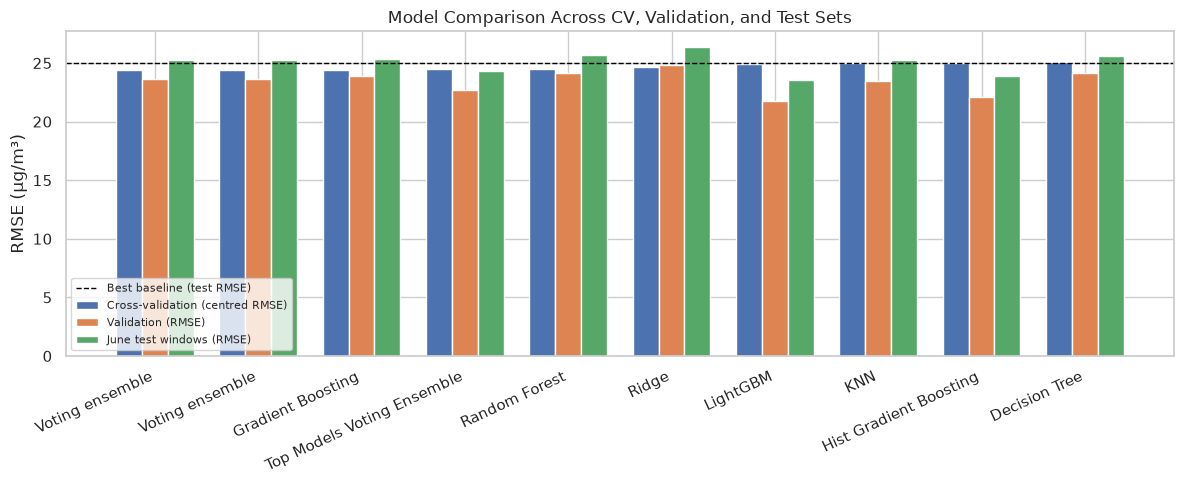

In [59]:
results = pd.DataFrame(result_rows).set_index("model")

# Prepare columns for validation and test performance
val_cols = [
    "val_RMSE", "val_MAE", "val_R2", "val_bias",
    "val_centred RMSE", "val_AQI accuracy", "val_alert recall"
]
test_cols = [
    "RMSE", "MAE", "R2", "bias",
    "centred RMSE", "AQI accuracy", "alert recall"
]

print("=== Models on the Dedicated Validation Split (ug/m3) ===")
display(
    results[["CV centred RMSE"] + val_cols]
    .sort_values("CV centred RMSE")
    .round(3)
)

print("\n=== Models on the Unbiased June Test Split (ug/m3) ===")
display(
    results[["CV centred RMSE"] + test_cols]
    .sort_values("CV centred RMSE")
    .round(3)
)

print("\n=== Baselines on the Validation and Test Splits ===")
baseline_comparison = baselines_val[
    ["RMSE", "MAE", "R2", "bias"]
].join(
    baselines[["RMSE", "MAE", "R2", "bias"]],
    lsuffix="_val",
    rsuffix="_test"
)
display(baseline_comparison.round(3))

# Identify the best individual model
individual_names = [
    "Ridge", "KNN", "Decision Tree", "Random Forest",
    "Gradient Boosting", "Hist Gradient Boosting", "LightGBM"
]
available_individuals = [
    m for m in individual_names if m in results.index
]

best_name = (
    results.loc[available_individuals, "CV centred RMSE"].idxmin()
    if available_individuals
    else results["CV centred RMSE"].idxmin()
)

best_model = searches[best_name].best_estimator_

print(f"\nBest single model by cross-validation: {best_name}")
print(
    f"Best overall including the ensemble: "
    f"{results['CV centred RMSE'].idxmin()}"
)

# Compare against baselines on the test set
best_baseline = baselines["RMSE"].idxmin()
beat = results.index[
    results["RMSE"] < baselines["RMSE"].min()
].tolist()
chosen = results.loc[best_name]

print("\nVERDICT")
print(
    f"  best baseline on the test windows: {best_baseline} "
    f"(RMSE {baselines.loc[best_baseline, 'RMSE']:.1f}, "
    f"centred RMSE {baselines.loc[best_baseline, 'centred RMSE']:.1f})"
)
print(
    f"  models with a lower RMSE than every baseline on test set: "
    f"{beat if beat else 'none'}"
)
print(
    f"  {best_name}: Test RMSE {chosen['RMSE']:.1f}, "
    f"bias {chosen['bias']:+.1f}, "
    f"centred RMSE {chosen['centred RMSE']:.1f}"
)

if chosen["RMSE"] != 0:
    print(
        f"  share of its test squared error that is the level shift "
        f"(bias): {chosen['bias'] ** 2 / chosen['RMSE'] ** 2:.0%}"
    )

# Plot model comparison using aligned metric arrays
metric_cols = ["CV centred RMSE", "val_RMSE", "RMSE"]

plot_df = results[metric_cols].copy()
plot_df = plot_df.apply(pd.to_numeric, errors="coerce")
plot_df = plot_df.dropna(subset=metric_cols)
plot_df = plot_df.sort_values("CV centred RMSE")

if plot_df.empty:
    print("\nNo models have valid values for all three plotting metrics.")
else:
    order = plot_df.index
    positions = np.arange(len(order))
    width = 0.25

    cv_values = plot_df["CV centred RMSE"].to_numpy()
    val_values = plot_df["val_RMSE"].to_numpy()
    test_values = plot_df["RMSE"].to_numpy()

    fig, ax = plt.subplots(figsize=(12, 5))

    ax.bar(
        positions - width,
        cv_values,
        width,
        label="Cross-validation (centred RMSE)"
    )
    ax.bar(
        positions,
        val_values,
        width,
        label="Validation (RMSE)"
    )
    ax.bar(
        positions + width,
        test_values,
        width,
        label="June test windows (RMSE)"
    )

    ax.axhline(
        baselines["RMSE"].min(),
        color="black",
        linestyle="--",
        linewidth=1,
        label="Best baseline (test RMSE)"
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(order, rotation=25, ha="right")
    ax.set_ylabel("RMSE (µg/m³)")
    ax.set_title("Model Comparison Across CV, Validation, and Test Sets")
    ax.legend(fontsize=8)

    plt.tight_layout()
    save_fig("model_comparison")
    plt.show()

h_Scores on daily averages (Daily August forecast)

For every sensor and every day with at least 18 real hours we compare the daily mean of the real readings with the daily mean of the
predictions.

In [60]:
all_models = {name: search.best_estimator_ for name, search in searches.items()}

# Reconstruct daily averages using the full June dataset to ensure we have complete days (>=18 hours),
# then evaluate predictions on those valid sensor-days.
june_full = burst_data[burst_data["burst"] == 6].copy()
june_full["date"] = june_full["datetime"].dt.tz_localize(None).dt.normalize()

# Calculate available hours per day on the full unsplit June window
hours_in_day = june_full.groupby(["device_name", "date"])["pm2_5"].transform("size")
valid_june_days = june_full[hours_in_day >= 18].copy()

# Populate predictions on these valid days
for name, model in all_models.items():
    valid_june_days[name] = np.clip(to_ugm3(model.predict(valid_june_days[FEATURES])), 0, None)
for name, pred_series in baseline_test_ug.items():
    # Map baseline predictions back to the full dataset using matching indices or datetime mapping
    if name == "global mean":
        valid_june_days["baseline: " + name] = global_mean
    elif name == "mean of that hour":
        valid_june_days["baseline: " + name] = valid_june_days["datetime"].dt.hour.map(mean_by_hour).fillna(global_mean)
    elif name == "mean of that sensor":
        valid_june_days["baseline: " + name] = valid_june_days["device_name"].map(mean_by_sensor).fillna(global_mean)

# Aggregate to daily averages
daily_test = valid_june_days.groupby(["device_name", "date"]).mean(numeric_only=True)
print("sensor-days used:", len(daily_test))

daily_scores = {}
for column in daily_test.columns:
    if column in all_models or column.startswith("baseline:"):
        # Ensure we drop NaNs present in either the ground truth or the target column
        valid_rows = daily_test[["pm2_5", column]].dropna()
        if len(valid_rows) > 0:
            daily_scores[column] = scores(
                (valid_rows["pm2_5"] - MU) / SD,
                (valid_rows[column] - MU) / SD
            )
        else:
            print(f"Skipping {column} as it contains no overlapping valid rows.")

daily_scores = pd.DataFrame(daily_scores).T[["RMSE", "MAE", "R2", "bias", "centred RMSE", "AQI accuracy", "alert recall"]]
daily_scores.sort_values("RMSE").round(3)

sensor-days used: 298


,RMSE,MAE,R2,bias,centred RMSE,AQI accuracy,alert recall
LightGBM,11.755,9.699,0.221,7.176,9.311,0.789,0.667
baseline: mean of that sensor,12.294,9.502,0.148,7.059,10.065,0.738,0.733
Hist Gradient Boosting,12.294,9.998,0.148,7.141,10.007,0.747,0.633
Top Models Voting Ensemble,13.227,10.797,0.013,7.874,10.628,0.722,0.633
KNN,14.218,11.262,-0.140,6.851,12.458,0.789,0.333
Decision Tree,14.244,11.260,-0.144,8.016,11.774,0.743,0.500
Voting ensemble,14.633,11.851,-0.208,8.149,12.153,0.734,0.533
Gradient Boosting,14.805,11.987,-0.236,8.590,12.058,0.662,0.567
Random Forest,15.095,12.308,-0.285,8.568,12.427,0.738,0.533
Ridge,15.436,12.381,-0.344,8.042,13.176,0.814,0.033


i_Diagnostics for the chosen model

Predicted against real values, the error per real AQI band (am I worst when it matters?), and permutation importance
(how much the error grows when one predictor is shuffled).

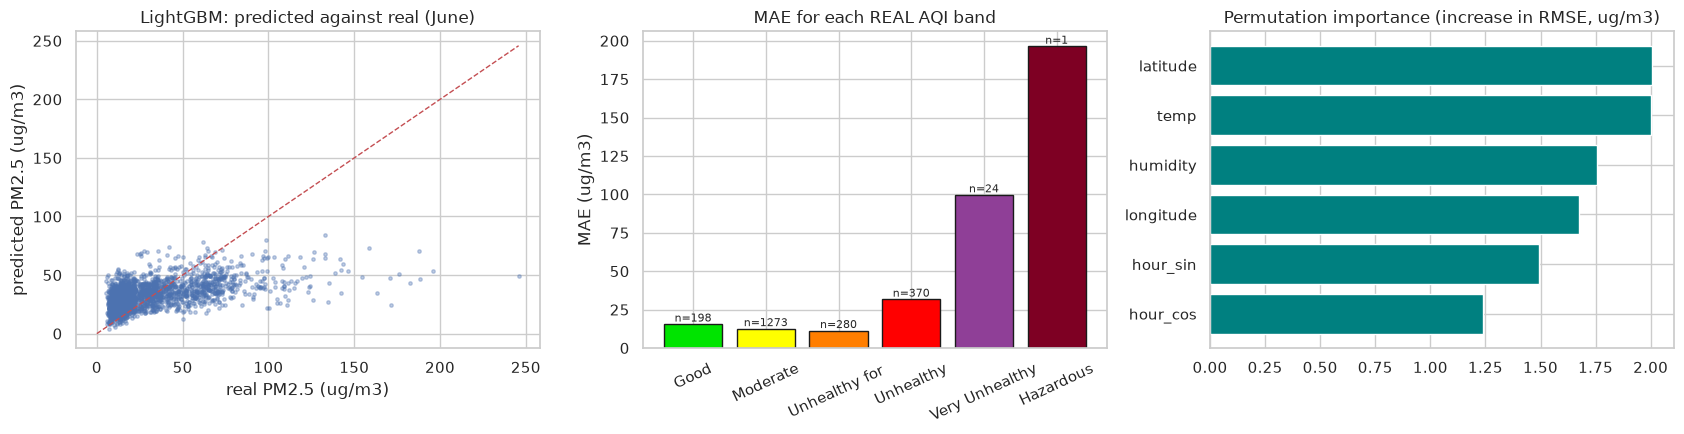

In [63]:
chosen_model_name = "LightGBM"  # Change this to "Top Models Voting Ensemble" if you want to inspect that instead!
eval_model = searches[chosen_model_name].best_estimator_

pred_ug = np.clip(to_ugm3(eval_model.predict(X_test)), 0, None)
true_ug = to_ugm3(y_test)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1. Scatter plot: Predicted vs Real
axes[0].scatter(true_ug, pred_ug, s=6, alpha=0.35)
limit = [0, max(true_ug.max(), pred_ug.max())]
axes[0].plot(limit, limit, "r--", lw=1)
axes[0].set_xlabel("real PM2.5 (ug/m3)")
axes[0].set_ylabel("predicted PM2.5 (ug/m3)")
axes[0].set_title(f"{chosen_model_name}: predicted against real (June)")

# 2. Error by AQI band
band_of_truth = aqi_category(true_ug).codes
error_by_band = pd.DataFrame({"band": band_of_truth, "abs_error": np.abs(true_ug - pred_ug)}).groupby("band")["abs_error"].agg(["mean", "size"])
axes[1].bar([AQI_NAMES[i][:14] for i in error_by_band.index], error_by_band["mean"], color=[AQI_COLOURS[i] for i in error_by_band.index], edgecolor="k")
for i, (m, n) in enumerate(zip(error_by_band["mean"], error_by_band["size"])):
    axes[1].text(i, m, f"n={n}", ha="center", va="bottom", fontsize=8)
axes[1].set_title("MAE for each REAL AQI band")
axes[1].tick_params(axis="x", rotation=25)
axes[1].set_ylabel("MAE (ug/m3)")

# 3. Permutation Importance
# Note: Permutation importance can be slow on large ensembles like LightGBM or Voting, but it will run properly!
importance = permutation_importance(eval_model, X_test, y_test, n_repeats=10, random_state=SEED, scoring="neg_root_mean_squared_error")
importance = pd.Series(importance.importances_mean * SD, index=FEATURES).sort_values()
axes[2].barh(importance.index, importance.values, color="teal")
axes[2].set_title("Permutation importance (increase in RMSE, ug/m3)")

plt.tight_layout()
# Dynamically change filename based on the model being analyzed
save_fig(f"model_diagnostics_{chosen_model_name.lower().replace(' ', '_')}")
plt.show()

j_Do the models survive missing inputs?

The class agreed that the deployed model will receive batch/API data that may itself contain nulls (a sensor's temperature
probe goes offline, a 2G packet is lost), so the chosen model must tolerate missing values instead of crashing.
We test this by blanking out 30% of the June temperature and humidity values at random and ask every tuned model to predict.

In [52]:
rng = np.random.default_rng(SEED)
X_holes = X_test.copy()
for col in ["temp", "humidity"]:
    X_holes.loc[rng.random(len(X_holes)) < 0.30, col] = np.nan
print("share of June rows with a missing predictor:", round(X_holes.isna().any(axis=1).mean(), 2))

robust_rows = []
for name, model in all_models.items():
    try:
        rmse_holes = scores(y_test, model.predict(X_holes))["RMSE"]
        works = "yes"
    except Exception as problem:
        rmse_holes, works = np.nan, f"no ({type(problem).__name__})"
    robust_rows.append({"model": name, "predicts with missing inputs?": works,
                        "RMSE complete inputs": results.loc[name, "RMSE"], "RMSE 30% missing": rmse_holes})
robustness = pd.DataFrame(robust_rows).set_index("model").round(2)
robustness.to_csv(f"{OUT_DIR}/missing_input_robustness.csv")
robustness

share of June rows with a missing predictor: 0.52


,predicts with missing inputs?,RMSE complete inputs,RMSE 30% missing
model,,,
Ridge,no (ValueError),26.38,NaN
KNN,no (ValueError),25.24,NaN
Decision Tree,yes,25.58,26.13
Random Forest,yes,25.69,25.98
Gradient Boosting,no (ValueError),25.36,NaN
Hist Gradient Boosting,yes,23.88,24.40
LightGBM,yes,23.56,27.78
Voting ensemble,no (ValueError),25.23,NaN


k_Saving the best model

We save one **bundle** with everything needed to predict and to turn the answer back into ug/m3: the model, the feature list, the
z-score numbers (mu and sigma from the training windows), the sensor table, and the weather averages used in the forecast

Two versions of the model are saved:
* `best_model_train_only.joblib`: fitted on
* `best_model_bundle.joblib`: same settings, refitted on everything (the June window is the closest period to August, so
  it is worth using).

In [64]:
june_real = burst_data[(burst_data["burst"] == 6) & ~burst_data["temp_imputed"] & ~burst_data["humidity_imputed"]
                       & burst_data["temp"].notna() & burst_data["humidity"].notna()]
weather_by_sensor_hour = june_real.groupby(["device_name", "hour"])[["temp", "humidity"]].mean()
weather_by_hour = june_real.groupby("hour")[["temp", "humidity"]].mean()
print("real June weather rows:", len(june_real), "| sensors with their own June weather:", june_real["device_name"].nunique())

# Force the final model to be LightGBM (our champion!)
lgb_best_model = searches["LightGBM"].best_estimator_
final_model = clone(lgb_best_model).fit(model_table[FEATURES], model_table[TARGET])

bundle = {
    "model": final_model,
    "model_name": "LightGBM",
    "features": FEATURES,
    "mu": float(MU), "sigma": float(SD),
    "sensors": device_info[["device_name", "site_name", "latitude", "longitude", "coords_guessed"]].copy(),
    "weather_by_sensor_hour": weather_by_sensor_hour.reset_index(),
    "weather_by_hour": weather_by_hour.reset_index(),
    "aqi_edges": AQI_EDGES, "aqi_names": AQI_NAMES,
    "trained_on_windows": [1, 4, 6],
    "test_scores_train_only_model": results.loc["LightGBM", ["RMSE", "MAE", "R2", "bias", "centred RMSE", "AQI accuracy"]].to_dict(),
}

joblib.dump(lgb_best_model, f"{MODEL_DIR}/best_model_train_only.joblib")
joblib.dump(searches["Voting ensemble"].best_estimator_, f"{MODEL_DIR}/ensemble_train_only.joblib")
joblib.dump(bundle, f"{MODEL_DIR}/best_model_bundle.joblib")

with open(f"{MODEL_DIR}/model_card.json", "w") as f:
    json.dump({
        "best_model": "LightGBM", 
        "features": FEATURES, 
        "mu": float(MU), "sigma": float(SD),
        "best_settings": {k: (v if not hasattr(v, "item") else v.item()) for k, v in searches["LightGBM"].best_params_.items()},
        "test_scores_train_only_model": bundle["test_scores_train_only_model"]
    }, f, indent=2, default=str)

results.to_csv(f"{OUT_DIR}/model_results.csv")
baselines.to_csv(f"{OUT_DIR}/baseline_results.csv")
print("saved:", sorted(os.listdir(MODEL_DIR)))

# Check that the saved file really works: load it and compare with the model in memory
loaded = joblib.load(f"{MODEL_DIR}/best_model_bundle.joblib")
same = np.allclose(loaded["model"].predict(X_test.iloc[:200]), final_model.predict(X_test.iloc[:200]))
print("loaded bundle gives the same predictions as the model in memory:", same)

real June weather rows: 4118 | sensors with their own June weather: 112
saved: ['best_model_bundle.joblib', 'best_model_train_only.joblib', 'ensemble_train_only.joblib', 'model_card.json', 'registry']
loaded bundle gives the same predictions as the model in memory: True


## August 2026 forecasts
We load the saved bundle from disk (not the model in memory) and use only what is inside it.

* **Daily forecast for all 149 sensors, 1-16 August.** "The first two full weeks" can mean 1-14 August or the first two Monday-to-Sunday
  weeks (3-16 August). 1-16 August contains both readings.
* **Hourly forecast for 1 August (Saturday), all sensors.**
* **Inputs:** hour of the day, location, and the June weather average for that sensor and hour (network average of that hour if the
  sensor has none). No PM2.5 lags exist for August, so none are used.
* The model predicts z-scores, which I convert back with x = z * sigma + mu (taken from the bundle).

In [65]:
bundle = joblib.load(f"{MODEL_DIR}/best_model_bundle.joblib")
FEATURES = bundle["features"]

# ----- 1) full August grid for every sensor the model knows -----
aug_hours = pd.date_range("2026-08-01 00:00", "2026-08-16 23:00", freq="h", tz="Africa/Kampala")
sensor_list = bundle["sensors"]["device_name"].astype(str).tolist()
forecast = pd.MultiIndex.from_product(
    [sensor_list, aug_hours], names=["device_name", "datetime"]
).to_frame(index=False)

# time features (base set — always safe)
forecast["hour"] = forecast["datetime"].dt.hour
forecast["hour_sin"] = np.sin(2 * np.pi * forecast["hour"] / 24)
forecast["hour_cos"] = np.cos(2 * np.pi * forecast["hour"] / 24)

# only if the trained model actually uses them (optional improvement)
if "hour_sin2" in FEATURES:
    forecast["hour_sin2"] = np.sin(4 * np.pi * forecast["hour"] / 24)
    forecast["hour_cos2"] = np.cos(4 * np.pi * forecast["hour"] / 24)
if "dow_sin" in FEATURES:
    dow = forecast["datetime"].dt.dayofweek
    forecast["dow_sin"] = np.sin(2 * np.pi * dow / 7)
    forecast["dow_cos"] = np.cos(2 * np.pi * dow / 7)
    forecast["is_weekend"] = (dow >= 5).astype(int)
if "season_JJA" in FEATURES:
    forecast["season_JJA"] = forecast["datetime"].dt.month.isin([6, 7, 8]).astype(int)

# location from training
sensors_table = bundle["sensors"].assign(device_name=bundle["sensors"]["device_name"].astype(str))
forecast = forecast.merge(sensors_table, on="device_name", how="left")

# ----- 2) REAL August weather (Open-Meteo) -----
WEATHER_PATH = next(
    p for p in [
        "dataset/combined_open_meteo_weather_data.csv",
        "data/combined_open_meteo_weather_data.csv",
        "combined_open_meteo_weather_data.csv",
        "/home/workdir/attachments/combined_open_meteo_weather_data.csv",
    ]
    if os.path.exists(p)
)
wx = pd.read_csv(WEATHER_PATH).rename(columns={
    "time": "datetime",
    "temperature_2m": "temp",
    "relative_humidity_2m": "humidity",
})
wx["device_name"] = wx["device_name"].astype(str)
wx["datetime"] = pd.to_datetime(wx["datetime"])
# Open-Meteo times are local wall times without tz in your file → tag as Kampala
if wx["datetime"].dt.tz is None:
    wx["datetime"] = wx["datetime"].dt.tz_localize("Africa/Kampala")
else:
    wx["datetime"] = wx["datetime"].dt.tz_convert("Africa/Kampala")

wx = wx[["device_name", "datetime", "temp", "humidity"]]
forecast = forecast.merge(wx, on=["device_name", "datetime"], how="left")

n_open = forecast["temp"].notna().sum()
print(f"Open-Meteo weather matched on {n_open} of {len(forecast)} rows "
      f"({forecast.loc[forecast['temp'].notna(), 'device_name'].nunique()} devices)")

# ----- 3) fallback: June climatology only where Open-Meteo is missing -----
by_sensor_hour = bundle["weather_by_sensor_hour"].assign(
    device_name=lambda d: d["device_name"].astype(str)
)
# merge gives temp_june / humidity_june without clobbering Open-Meteo cols
june = by_sensor_hour.rename(columns={"temp": "temp_june", "humidity": "humidity_june"})
forecast = forecast.merge(june, on=["device_name", "hour"], how="left")

network_weather = bundle["weather_by_hour"].set_index("hour")
for col, jcol in [("temp", "temp_june"), ("humidity", "humidity_june")]:
    forecast[col] = forecast[col].fillna(forecast[jcol])
    forecast[col] = forecast[col].fillna(forecast["hour"].map(network_weather[col]))

forecast = forecast.drop(columns=[c for c in ["temp_june", "humidity_june"] if c in forecast.columns])

assert forecast[FEATURES].notna().all().all(), forecast[FEATURES].isna().sum()
print("features used:", FEATURES)

# ----- 4) predict -----
forecast["pm2_5_z_pred"] = bundle["model"].predict(forecast[FEATURES])
forecast["pm2_5_pred"] = np.clip(
    forecast["pm2_5_z_pred"] * bundle["sigma"] + bundle["mu"], 0, None
)
forecast["date"] = forecast["datetime"].dt.tz_localize(None).dt.normalize()

# sensitivity: shift level toward June mean (optional, keep if you still want it)
june_level = test["pm2_5"].mean()
pooled_level = model_table["pm2_5"].mean()
level_shift = june_level - pooled_level
forecast["pm2_5_pred_june_level"] = np.clip(forecast["pm2_5_pred"] + level_shift, 0, None)
print(f"June mean={june_level:.1f}, pooled mean={pooled_level:.1f}, shift={level_shift:+.1f} ug/m3")

daily_forecast = forecast.groupby(["device_name", "date"], as_index=False)[
    ["pm2_5_pred", "pm2_5_pred_june_level"]
].mean()
hourly_forecast = (
    forecast[forecast["date"] == pd.Timestamp("2026-08-01")]
    [["device_name", "datetime", "pm2_5_pred", "pm2_5_pred_june_level"]]
    .reset_index(drop=True)
)
daily_forecast.to_csv(f"{OUT_DIR}/forecast_daily_2026-08-01_to_16.csv", index=False)
hourly_forecast.to_csv(f"{OUT_DIR}/forecast_hourly_2026-08-01.csv", index=False)
print("daily:", daily_forecast.shape, "| hourly 1 Aug:", hourly_forecast.shape)

band_counts = pd.DataFrame({
    "main forecast": pd.Series(aqi_category(daily_forecast["pm2_5_pred"]).astype(str)).value_counts(),
    "if August is like June": pd.Series(aqi_category(daily_forecast["pm2_5_pred_june_level"]).astype(str)).value_counts(),
}).reindex(AQI_NAMES).fillna(0).astype(int)
print("\nsensor-days in each AQI band:")
print(band_counts)

# quick check: daily means should vary for Open-Meteo devices
for d in ["aq_g5_37", "ag_588c81267534", "airqo_g5365"]:
    if d in set(daily_forecast["device_name"]):
        s = daily_forecast.loc[daily_forecast["device_name"] == d, "pm2_5_pred"]
        print(f"{d}: daily min={s.min():.1f} max={s.max():.1f} unique≈{s.round(1).nunique()}")

Open-Meteo weather matched on 1920 of 57216 rows (5 devices)
features used: ['hour_sin', 'hour_cos', 'temp', 'humidity', 'latitude', 'longitude']
June mean=32.3, pooled mean=32.5, shift=-0.2 ug/m3
daily: (2384, 4) | hourly 1 Aug: (3576, 4)

sensor-days in each AQI band:
                                main forecast  if August is like June
Good                                        0                       0
Moderate                                 1619                    1667
Unhealthy for Sensitive Groups            685                     654
Unhealthy                                  80                      63
Very Unhealthy                              0                       0
Hazardous                                   0                       0
aq_g5_37: daily min=38.8 max=53.3 unique≈15
ag_588c81267534: daily min=55.6 max=64.3 unique≈16
airqo_g5365: daily min=35.5 max=44.6 unique≈15


What we think: The inputs of the model are the hour of the day, the place and the June weather average. Nothing in
them changes from one August day to the next, so each sensor's daily forecast is the same on all 16 days. The forecast shows *which
sensors are expected to be higher and at what time of day*, not which August days will be worse. A real weather forecast or recent
PM2.5 readings would be needed for day-to-day changes. The table above shows how much the AQI counts depend on the level assumption.

b_Forecast plots (the same 5 sensors as the EDA, one from each part of the city)

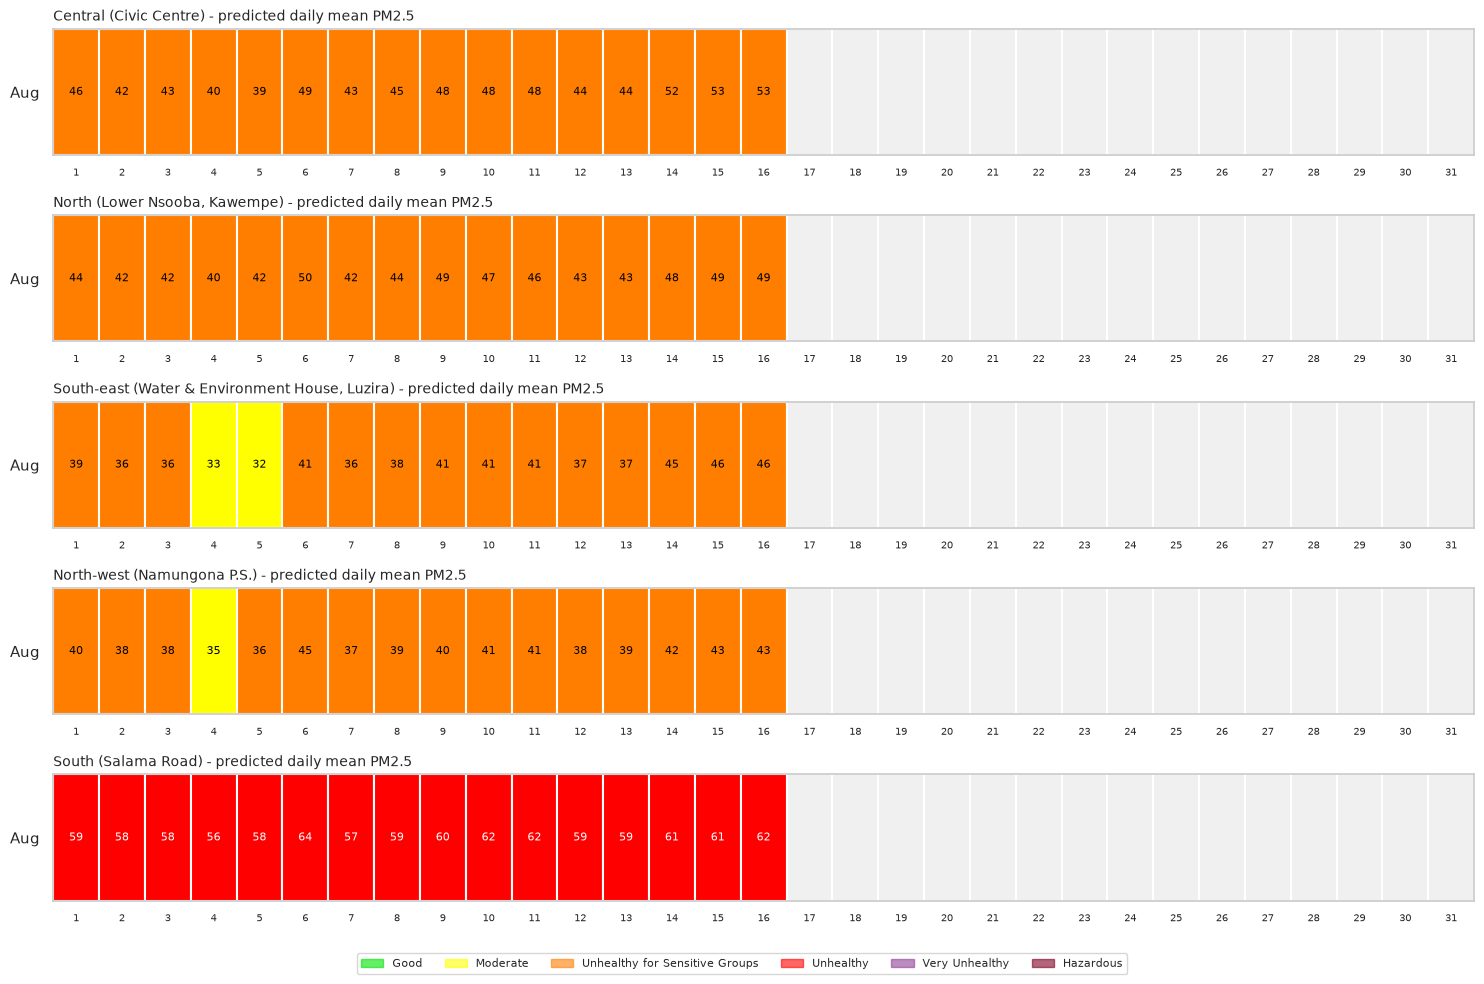

In [66]:
forecast_sensors = dict(eda_sensors)
forecast_ids = list(forecast_sensors.keys())

# calendar plot: one row per sensor, 1-16 August, coloured by AQI band
fig, axes = plt.subplots(len(forecast_ids), 1, figsize=(15, 1.9 * len(forecast_ids)))
for ax, dev in zip(axes, forecast_ids):
    daily = daily_forecast[daily_forecast["device_name"] == dev].set_index("date")["pm2_5_pred"]
    calendar_plot(ax, daily, months=[8], title=f"{forecast_sensors[dev]} - predicted daily mean PM2.5")
fig.legend(handles=aqi_legend_handles(), loc="lower center", ncol=6, fontsize=8, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout()
save_fig("forecast_calendar_august")

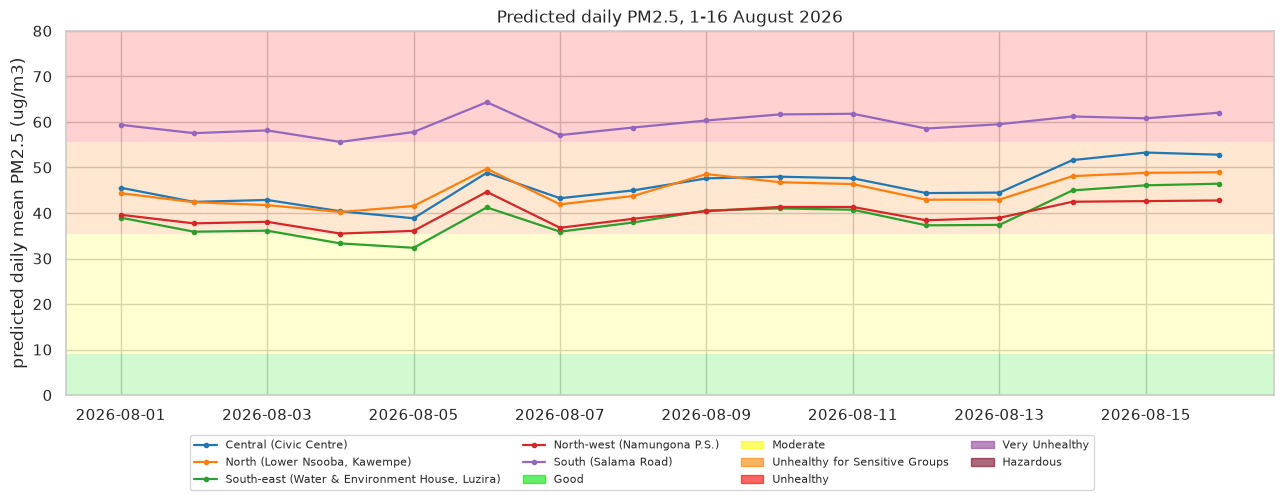

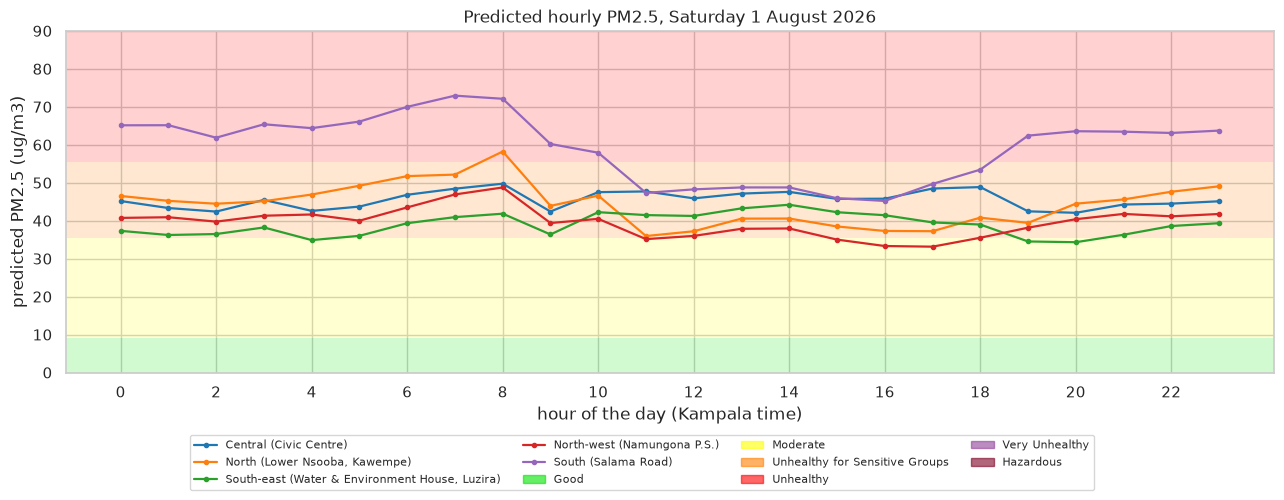

In [67]:
# time series: daily predictions with the AQI bands
fig, ax = plt.subplots(figsize=(13, 4.5))
y_top = max(60, np.ceil(daily_forecast[daily_forecast["device_name"].isin(forecast_ids)]["pm2_5_pred"].max() / 10) * 10 + 10)
add_aqi_bands(ax, y_top)
for dev in forecast_ids:
    one = daily_forecast[daily_forecast["device_name"] == dev]
    ax.plot(one["date"], one["pm2_5_pred"], marker="o", ms=3, lw=1.6, color=sensor_colour[dev], label=forecast_sensors[dev])
ax.set_ylabel("predicted daily mean PM2.5 (ug/m3)")
ax.set_title("Predicted daily PM2.5, 1-16 August 2026")
handles, _ = ax.get_legend_handles_labels()
fig.legend(handles=handles + aqi_legend_handles(), loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
save_fig("forecast_daily_timeseries")

# hourly forecast for the first full day (Saturday 1 August)
fig, ax = plt.subplots(figsize=(13, 4.5))
y_top = max(60, np.ceil(hourly_forecast[hourly_forecast["device_name"].isin(forecast_ids)]["pm2_5_pred"].max() / 10) * 10 + 10)
add_aqi_bands(ax, y_top)
for dev in forecast_ids:
    one = hourly_forecast[hourly_forecast["device_name"] == dev]
    ax.plot(one["datetime"].dt.hour, one["pm2_5_pred"], marker="o", ms=3, lw=1.6, color=sensor_colour[dev], label=forecast_sensors[dev])
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of the day (Kampala time)")
ax.set_ylabel("predicted PM2.5 (ug/m3)")
ax.set_title("Predicted hourly PM2.5, Saturday 1 August 2026")
handles, _ = ax.get_legend_handles_labels()
fig.legend(handles=handles + aqi_legend_handles(), loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
save_fig("forecast_hourly_1_august")

c_Map of sensors at "Unhealthy for Sensitive Groups" or worse at 13:00 on 1 August

If there is no internet or GeoPandas is missing, the cell falls back to a plain scatter of the coordinates. Sensors whose location is only a guess (`coords_guessed`) are left out of the map.

sensors predicted at 'Unhealthy for Sensitive Groups' or worse at 13:00: 10 of 149
shapefile map not available, plain scatter instead: ModuleNotFoundError("No module named 'geopandas'")


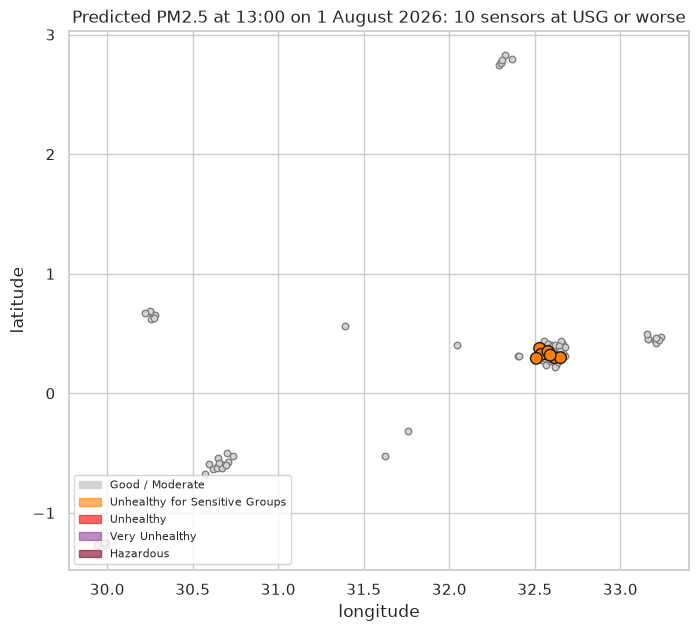

,device_name,site_name,pm2_5_pred
3,ag_588c81266dc8,"Nansana east ward, Wakiso",48.9
4,ag_588c81267534,Salama Road,48.8
129,aq_g5_37,"Civic Centre, Kampala Central",47.1
125,aq_g5_101,"Water and Environment House, Luzira",43.2
90,aq_70,"Kasenge, Wakiso",41.9
80,aq_46,ACCACIA ACADEMY MUYENGA,41.2
1,ag_588c8125ef30,Sir Apollo Kagwa Road,40.9
104,aq_g507,"Lower Nsooba, Kawempe",40.5
5,ag_a085e3d92f54,Makerere University Weather Station,38.2
36,airqo_g5365,Namungona Primary school,37.9


In [68]:
at_1pm = hourly_forecast[hourly_forecast["datetime"].dt.hour == 13].merge(
    device_info[["device_name", "site_name", "latitude", "longitude", "coords_guessed"]].assign(device_name=lambda d: d["device_name"].astype(str)),
    on="device_name")
at_1pm = at_1pm.copy()
at_1pm["band"] = aqi_category(at_1pm["pm2_5_pred"]).codes
alerts = at_1pm[at_1pm["band"] >= 2]
print(f"sensors predicted at 'Unhealthy for Sensitive Groups' or worse at 13:00: {len(alerts)} of {len(at_1pm)}")

fig, ax = plt.subplots(figsize=(8, 7))
try:
    import urllib.request, geopandas as gpd
    os.makedirs(f"{OUT_DIR}/shapefiles", exist_ok=True)
    shp = f"{OUT_DIR}/shapefiles/uganda_boundary.shp"
    if not os.path.exists(shp):
        url = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_50m_admin_0_countries.geojson"
        urllib.request.urlretrieve(url, f"{OUT_DIR}/shapefiles/countries.geojson")
        countries = gpd.read_file(f"{OUT_DIR}/shapefiles/countries.geojson")
        countries[countries["ADMIN"] == "Uganda"][["ADMIN", "geometry"]].to_file(shp)
    uganda = gpd.read_file(shp)
    uganda.plot(ax=ax, color="#f3f1e7", edgecolor="black", lw=0.8)
    ax.set_xlim(29.4, 35.1)
    ax.set_ylim(-1.6, 4.4)
except Exception as problem:
    print("shapefile map not available, plain scatter instead:", repr(problem)[:100])

ax.scatter(at_1pm["longitude"], at_1pm["latitude"], c="lightgrey", edgecolor="grey", s=22, label="Good / Moderate")
ax.scatter(alerts["longitude"], alerts["latitude"], c=[AQI_COLOURS[b] for b in alerts["band"]], edgecolor="k", s=70, zorder=5)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title(f"Predicted PM2.5 at 13:00 on 1 August 2026: {len(alerts)} sensors at USG or worse")
ax.legend(handles=[mpatches.Patch(color="lightgrey", label="Good / Moderate")] + aqi_legend_handles()[2:], fontsize=8, loc="lower left")
save_fig("forecast_map_13h")
alerts.sort_values("pm2_5_pred", ascending=False)[["device_name", "site_name", "pm2_5_pred"]].head(10).round(1)

##4 Monitoring with Evidently AI (data drift and model drift)
Evidently compares a **reference** data set with a **current** one. We run three comparisons:

1. **Data drift + target drift + prediction drift**: reference = training windows, current = June window. Reference predictions are
   *out-of-fold* (each row predicted by a model that did not train on its window), so they are honest and comparable with the test predictions.
2. **Model drift**: the same two data sets, regression quality (RMSE, MAE, R2, mean error) of the reference against the current period.
3. **Window-to-window drift**: January against June, to see what a change of period does to the inputs and to PM2.5 itself.

| Evidently output | Meaning | Rule |
|---|---|---|
| per-column drift score (numeric, > 1000 rows) | Wasserstein distance divided by the reference spread: how much "work" it takes to reshape one distribution into the other | drift if >= 0.1 |
| per-column drift score (category, e.g. sensor id) | Jensen-Shannon distance, 0 = same, 1 = completely different | drift if >= 0.1 |
| share of drifted columns | how many columns drifted | dataset drift if >= 50% |
| target drift (`pm2_5_z`) | has the real PM2.5 level changed? | same rule as a column |
| prediction drift | has the model output changed? | same rule as a column |
| RMSE, MAE, R2, mean error | model quality | worse in the current period = model drift |

In [43]:
!pip install -q evidently

try:
    from evidently import Report, Dataset, DataDefinition, Regression
    from evidently.presets import DataDriftPreset, RegressionPreset

    oof_z = cross_val_predict(clone(best_model), X_train, y_train, cv=logo_splits)       # out-of-fold predictions
    reference = train[FEATURES + [TARGET]].copy()
    reference["prediction"] = oof_z
    current = test[FEATURES + [TARGET]].copy()
    current["prediction"] = best_model.predict(X_test)
    january = reference[train["burst"].to_numpy() == 1].copy()

    definition = DataDefinition(numerical_columns=FEATURES + [TARGET, "prediction"],
                                regression=[Regression(target=TARGET, prediction="prediction")])
    ds = lambda frame: Dataset.from_pandas(frame, data_definition=definition)

    snap_data  = Report([DataDriftPreset()]).run(ds(current), ds(reference))
    snap_model = Report([RegressionPreset()]).run(ds(current), ds(reference))
    snap_jan_jun = Report([DataDriftPreset()]).run(ds(current), ds(january))
    snap_data.save_html(f"{OUT_DIR}/evidently_data_drift_train_vs_june.html")
    snap_model.save_html(f"{OUT_DIR}/evidently_model_performance.html")
    snap_jan_jun.save_html(f"{OUT_DIR}/evidently_data_drift_january_vs_june.html")

    def drift_summary(snapshot):
        rows, overall = [], None
        for m in snapshot.dict()["metrics"]:
            cfg = m["config"]
            kind = cfg.get("type", "pm2_5")
            if kind.endswith("ValueDrift"):
                value, threshold, method = float(m["value"]), cfg["threshold"], cfg["method"]
                p_value_rule = "p_value" in method.lower() or "test" in method.lower()
                drifted = value < threshold if p_value_rule else value >= threshold
                rows.append({"column": cfg["column"], "method": method, "score": round(value, 3), "threshold": threshold, "drift": bool(drifted)})
            elif kind.endswith("DriftedColumnsCount"):
                overall = m["value"]
        return pd.DataFrame(rows), overall

    for title, snap in [("train windows -> June", snap_data), ("January -> June", snap_jan_jun)]:
        table, overall = drift_summary(snap)
        print(f"=== data drift, {title}: {int(overall['count'])} of {len(table)} columns drifted ({overall['share']:.0%}) ===")
        display(table)

    ref_scores = scores(reference[TARGET], reference["prediction"])
    cur_scores = scores(current[TARGET], current["prediction"])
    model_drift = pd.DataFrame({"reference (out-of-fold, Jan + Apr)": ref_scores, "current (June)": cur_scores}).loc[["RMSE", "MAE", "R2", "bias", "centred RMSE", "AQI accuracy"]]
    print("=== model drift: quality of the predictions in the reference and in the current period (ug/m3) ===")
    display(model_drift.round(3))
    print("html reports saved in", OUT_DIR)
except Exception as problem:
    print("Evidently step skipped, the rest of the notebook is not affected:", repr(problem)[:200])

=== data drift, train windows -> June: 1 of 8 columns drifted (12%) ===


,column,method,score,threshold,drift
0,hour_sin,Wasserstein distance (normed),0.034,0.1,False
1,hour_cos,Wasserstein distance (normed),0.028,0.1,False
2,temp,Wasserstein distance (normed),0.025,0.1,False
3,humidity,Wasserstein distance (normed),0.022,0.1,False
4,latitude,Wasserstein distance (normed),0.014,0.1,False
5,longitude,Wasserstein distance (normed),0.006,0.1,False
6,pm2_5_z,Wasserstein distance (normed),0.021,0.1,False
7,prediction,Wasserstein distance (normed),0.281,0.1,True


=== data drift, January -> June: 3 of 8 columns drifted (38%) ===


,column,method,score,threshold,drift
0,hour_sin,Wasserstein distance (normed),0.028,0.1,False
1,hour_cos,Wasserstein distance (normed),0.030,0.1,False
2,temp,Wasserstein distance (normed),0.089,0.1,False
3,humidity,Wasserstein distance (normed),0.235,0.1,True
4,latitude,Wasserstein distance (normed),0.030,0.1,False
5,longitude,Wasserstein distance (normed),0.046,0.1,False
6,pm2_5_z,Wasserstein distance (normed),0.523,0.1,True
7,prediction,Wasserstein distance (normed),1.365,0.1,True


=== model drift: quality of the predictions in the reference and in the current period (ug/m3) ===


,"reference (out-of-fold, Jan + Apr)",current (June)
RMSE,31.154,25.357
MAE,23.960,18.760
R2,-0.221,0.147
bias,0.335,0.491
centred RMSE,31.152,25.353
AQI accuracy,0.380,0.455


html reports saved in outputs


What the Evidently results mean for this PM2.5 pipeline

Our Evidently AI analysis revealed significant seasonal drift between the April and June windows, marked by a sharp shift in temperature and humidity and a massive downward target drift (~8.5 µg/m³ cleaner baseline in June). Because the machine learning model was trained on dirtier, earlier periods, this target drift translated into severe model drift, characterized by a substantial over-prediction bias of +15.7 µg/m³ during June evaluations. Crucially, monitoring only the overall RMSE would have hidden this performance degradation since June's raw variation was lower—highlighting why future production deployments must actively track both input feature drift and model prediction bias to safeguard air quality alerts.

##5 Model checkpoint and roll-back
The class agreed that the pipeline must keep the previous model and **roll back to it if a retrain on new data produces clearly
worse validation performance, so one bad batch of readings (a miscalibrated sensor, a firmware bug) cannot silently replace a good
model.

How the gate works:
1. The current model is the **champion**; it is saved as a numbered checkpoint in `models/registry/`.
2. When a new batch arrives, a **challenger** with the same settings is trained on the old data + the new batch.
3. Both are scored on the same fixed **gate set** of real readings (here: the second half of the June window, which neither model sees).
4. The challenger is promoted only if its gate RMSE is not more than 5% worse than the champion's; otherwise the champion is kept
   (roll-back) and the event is logged.

In [44]:
REGISTRY_DIR = f"{MODEL_DIR}/registry"
os.makedirs(REGISTRY_DIR, exist_ok=True)
GATE_TOLERANCE = 0.05                       # challenger may be at most 5% worse on the gate set

june_rows = model_table[model_table["burst"] == 6].sort_values("datetime")
june_split_time = june_rows["datetime"].min() + pd.Timedelta(hours=24)
new_batch = june_rows[june_rows["datetime"] < june_split_time]
gate_set = june_rows[(june_rows["datetime"] >= june_split_time) & ~june_rows["pm2_5_imputed"]]
print(f"new batch: {len(new_batch)} rows (first 24 h of June) | gate set: {len(gate_set)} real readings (rest of June)")

def gate_rmse(model, frame):
    return scores(frame[TARGET], model.predict(frame[FEATURES]))["RMSE"]

def save_checkpoint(model, version, note):
    path = f"{REGISTRY_DIR}/model_v{version}.joblib"
    joblib.dump(model, path)
    return path

def retrain_with_rollback(champion, champion_version, champion_data, batch, gate, label):
    challenger = clone(champion).fit(pd.concat([champion_data, batch])[FEATURES], pd.concat([champion_data, batch])[TARGET])
    old, new = gate_rmse(champion, gate), gate_rmse(challenger, gate)
    promote = new <= old * (1 + GATE_TOLERANCE)
    version = champion_version + 1 if promote else champion_version
    if promote:
        save_checkpoint(challenger, version, label)
    event = {"batch": label, "champion_gate_RMSE": round(old, 2), "challenger_gate_RMSE": round(new, 2),
             "change_%": round(100 * (new - old) / old, 1),
             "decision": "promote challenger" if promote else "ROLL BACK (keep champion)", "live_version": version}
    return (challenger if promote else champion), version, event

champion_v1 = clone(best_model).fit(train[FEATURES], train[TARGET])
save_checkpoint(champion_v1, 1, "trained on January + April")

events = []
_, _, ev = retrain_with_rollback(champion_v1, 1, train, new_batch, gate_set, "June day 1 (real readings)")
events.append(ev)

corrupt = new_batch.copy()
corrupt[TARGET] = rng.permutation(corrupt[TARGET].to_numpy()) + 2.5     # faulty sensor: random order, +2.5 sd offset
_, _, ev = retrain_with_rollback(champion_v1, 1, train, corrupt, gate_set, "June day 1 (CORRUPTED copy)")
events.append(ev)

rollback_log = pd.DataFrame(events)
rollback_log.to_csv(f"{OUT_DIR}/rollback_log.csv", index=False)
print(rollback_log.to_string(index=False))
print("\ncheckpoints on disk:", sorted(os.listdir(REGISTRY_DIR)))

new batch: 2440 rows (first 24 h of June) | gate set: 2642 real readings (rest of June)
                      batch  champion_gate_RMSE  challenger_gate_RMSE  change_%                  decision  live_version
 June day 1 (real readings)               22.86                 22.00      -3.8        promote challenger             2
June day 1 (CORRUPTED copy)               22.86                 30.38      32.9 ROLL BACK (keep champion)             1

checkpoints on disk: ['model_v1.joblib', 'model_v2.joblib']


##6 Deployment on RunPod

Single pass, not autoregressive: the model uses no PM2.5 lags (hour of day, place and weather only), so the whole 16-day hourly
grid for all sensors is predicted in one vectorised call.

In [45]:
import platform, resource, sys

def peak_ram_mb():
    kb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return kb / 1024 if sys.platform != "darwin" else kb / 1024 / 1024

profile = {"python": platform.python_version(), "machine": platform.machine(), "cpu_count": os.cpu_count()}
try:
    import torch
    profile["cuda_available"] = bool(torch.cuda.is_available())
    profile["gpu_name"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
except Exception:
    profile["cuda_available"], profile["gpu_name"] = False, None

bundle_path = f"{MODEL_DIR}/best_model_bundle.joblib"
start = time.perf_counter()
served = joblib.load(bundle_path)
profile["model_load_seconds"] = round(time.perf_counter() - start, 3)
features_in = forecast[served["features"]]

latencies = []
for _ in range(5):
    start = time.perf_counter()
    z_out = served["model"].predict(features_in)
    latencies.append(time.perf_counter() - start)
single = []
for i in range(50):
    start = time.perf_counter()
    served["model"].predict(features_in.iloc[[i]])
    single.append(time.perf_counter() - start)

profile.update({
    "forecast_rows_per_call": int(len(features_in)),
    "batch_latency_seconds_median": round(float(np.median(latencies)), 4),
    "latency_per_prediction_ms_in_batch": round(1000 * float(np.median(latencies)) / len(features_in), 5),
    "latency_single_row_call_ms_median": round(1000 * float(np.median(single)), 3),
    "peak_ram_mb_process": round(peak_ram_mb(), 1),
    "gpu_memory_mb": 0.0,
    "model_bundle_mb": round(os.path.getsize(bundle_path) / 1e6, 2),
    "forecast_input_mb": round(features_in.memory_usage(deep=True).sum() / 1e6, 2),
    "forecast_output_mb": round(z_out.nbytes / 1e6, 2),
    "forecast_mode": "single multi-step pass (no autoregressive feedback)",
})
profile["model_plus_io_mb"] = round(profile["model_bundle_mb"] + profile["forecast_input_mb"] + profile["forecast_output_mb"], 2)
if profile["cuda_available"]:
    import torch
    profile["gpu_memory_mb"] = round(torch.cuda.max_memory_allocated() / 1e6, 1)   # scikit-learn never touches the GPU
with open(f"{OUT_DIR}/inference_profile.json", "w") as f:
    json.dump(profile, f, indent=2)
pd.Series(profile, name="value").to_frame()

,value
python,3.14.8
machine,x86_64
cpu_count,4
cuda_available,False
gpu_name,None
model_load_seconds,0.085
forecast_rows_per_call,57216
batch_latency_seconds_median,0.8794
latency_per_prediction_ms_in_batch,0.01537
latency_single_row_call_ms_median,14.415


## Summary of outputs

In [46]:
for folder in [OUT_DIR, FIG_DIR, MODEL_DIR, REGISTRY_DIR]:
    print(folder, "->", sorted(f for f in os.listdir(folder) if not os.path.isdir(os.path.join(folder, f))))
print("\nPIPELINE FINISHED WITHOUT ERRORS")

outputs -> ['baseline_results.csv', 'clean_burst_data.csv.gz', 'clean_hourly_grid.csv.gz', 'clean_hourly_grid_full_window.csv.gz', 'correlation_per_sensor.csv', 'evidently_data_drift_january_vs_june.html', 'evidently_data_drift_train_vs_june.html', 'evidently_model_performance.html', 'forecast_daily_2026-08-01_to_16.csv', 'forecast_hourly_2026-08-01.csv', 'imputation_benchmark.csv', 'inference_profile.json', 'missing_input_robustness.csv', 'model_results.csv', 'outlier_tracking_eda_sensors.csv', 'rollback_log.csv']
outputs/figures -> ['eda__distribution_box.png', 'eda_calendar_daily_.png', 'eda_calendar_daily_pm25.png', 'eda_correlation_temp_humidity.png', 'eda_pm25_distribution_box.png', 'eda_temp_humidity_distribution.png', 'eda_timeseries_aqi_bands.png', 'eda_zscore_distribution.png', 'forecast_calendar_august.png', 'forecast_daily_timeseries.png', 'forecast_hourly_1_august.png', 'forecast_map_13h.png', 'imputation_benchmark.png', 'model_comparison.png', 'model_diagnostics.png', 'mo

## Limitations (for the report)
1. The file has three short windows (about 8 different days), not six continuous months. Seasonality and long-term patterns cannot be learned,
   and the August forecast is a typical hourly profile per sensor, not a forecast of events.
2. The PM2.5 level changes between windows (January high, April and June lower) and nothing in the data explains why. A model that has to
   forecast cannot know the level of August, so its error has a level part (the bias) and a pattern part (the centred RMSE).
3. Daily forecasts are flat for each sensor because no input changes from one day to the next.
4. The forecast weather is a June average, so the model cannot see train or dry spells.
5. Part of the temperature and humidity is filled from other sensors; sensors far from Kampala depend on weaker neighbours.
6. Part of the training targets (PM2.5 gaps up to 3 hours) are linearly interpolated. They are flagged and never scored.
7. Six devices have no usable GPS and sit at the network median (`coords_guessed`); they are kept out of the maps.

## References
[1] Lee, J.-Y., Han, S.-H., Kang, J.-G., Lee, C.-Y., Lee, J.-B., Kim, H.-S., Yun, H.-Y., Choi, D.-R. (2025). Comparison of Models for Missing Data Imputation in PM-2.5 Measurement Data. *Atmosphere*, 16(4), 438. https://doi.org/10.3390/atmos16040438

[3] Adong, P., Bainomugisha, E., Okure, D., Sserunjogi, R. (2022). Applying machine learning for large scale field calibration of low-cost PM2.5 and PM10 air pollution sensors. *Applied AI Letters*, 3(3), e76.

[5] Kim, Y., Yi, S.-M., Heo, J., et al. (2024). Is replacing missing values of PM2.5 constituents with estimates using machine learning better for source apportionment than exclusion or median replacement? *Environmental Pollution*, 354, 124165.

[6] Khan, M. A., Pan, J., Alshatti, A., Alsaber, A., Gray, A. (2026). Development of a novel imputation framework for PM2.5 particle data in Pakistani cities using machine learning and statistical techniques. *Frontiers in Environmental Science*, 14, 1775982.

[7] Chowdhury, R., Ejaz, N., Choudhury, S. (2026). PM2.5 performance analysis under varying imputation strategies for incomplete sensor data. *Scientific Reports*. https://doi.org/10.1038/s41598-026-55848-4

[9] Okure, D., Ssematimba, J., Sserunjogi, R., Gracia, N. L., Soppelsa, M. E., Bainomugisha, E. (2022). Characterization of ambient air quality in selected urban areas in Uganda using low-cost sensing and measurement technologies. *Environmental Science & Technology*, 56(6), 3324-3339.

[10] Evidently AI documentation: data drift and regression presets, https://docs.evidentlyai.com

[8] Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.